In [1]:
# Comparison — Step 1: load every classifier's saved per-image results in one standard format.
# Reads saved artifacts only. No model is trained or re-evaluated.
# Images are always matched by ID, never by position.

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

CMP_PROJECT_PATH = Path(r"C:\Users\hadid\Ramen\ds-ml-project-template")
CMP_ARTIFACTS = CMP_PROJECT_PATH / "artifacts"
CMP_PIXELS_PER_IMAGE = 128 * 128
CMP_RANDOM_STATE = 43
CMP_DIR = CMP_ARTIFACTS / "classifier_comparison" / "comparison"
CMP_DIR.mkdir(parents=True, exist_ok=True)

CMP_MODEL_ORDER = [
    "LR", "LR + interactions", "Decision tree",
    "Random forest", "HGB", "XGBoost",
]
CMP_THRESHOLDS = {
    "LR": 0.10, "LR + interactions": 0.11, "Decision tree": 0.92,
    "Random forest": 0.17, "HGB": 0.13, "XGBoost": 0.14,
}

# Values reported in the individual notebooks (used only as a consistency check).
CMP_REPORTED_F2 = {
    ("LR", "Test"): 0.611569,
    ("LR + interactions", "Test"): 0.743009,
    ("Decision tree", "Outer"): 0.737575, ("Decision tree", "Test"): 0.722791,
    ("Random forest", "Outer"): 0.776136, ("Random forest", "Test"): 0.766812,
    ("HGB", "Outer"): 0.773866, ("HGB", "Test"): 0.766319,
    ("XGBoost", "Outer"): 0.772955, ("XGBoost", "Test"): 0.765123,
}

ID_COLUMNS = ("image_id", "patch_id", "sample_id")
PIXEL_COLUMNS = ("n_pixels", "pixels", "Pixels")
COUNT_COLUMNS = ["TN", "FP", "FN", "TP"]


def cmp_standardize(table, model, stage):
    """Return one row per image: Model, Stage, image_id, TN, FP, FN, TP."""
    table = pd.DataFrame(table).copy()
    id_column = next((c for c in ID_COLUMNS if c in table.columns), None)
    pixel_column = next((c for c in PIXEL_COLUMNS if c in table.columns), None)
    missing = [c for c in COUNT_COLUMNS if c not in table.columns]
    if id_column is None or missing:
        raise KeyError(f"{model} / {stage}: unexpected columns {list(table.columns)}")

    standard = pd.DataFrame({
        "Model": model,
        "Stage": stage,
        "image_id": table[id_column].astype(str).str.strip().to_numpy(),
        **{c: table[c].to_numpy(dtype=np.int64) for c in COUNT_COLUMNS},
    })

    totals = standard[COUNT_COLUMNS].sum(axis=1).to_numpy()
    assert (totals == CMP_PIXELS_PER_IMAGE).all(), (
        f"{model} / {stage}: not every image has 16,384 evaluated pixels."
    )
    if pixel_column is not None:
        assert np.array_equal(totals, table[pixel_column].to_numpy(dtype=np.int64)), (
            f"{model} / {stage}: pixel counts are inconsistent."
        )
    assert standard["image_id"].is_unique, f"{model} / {stage}: duplicate image IDs."
    return standard


def cmp_get(store, key, label):
    if key not in store:
        raise KeyError(f"{label}: '{key}' not found. Available keys: {sorted(store)}")
    return store[key]


def cmp_latest_folder(pattern):
    folders = sorted(CMP_ARTIFACTS.glob(pattern), key=lambda p: p.stat().st_mtime)
    if not folders:
        raise FileNotFoundError(f"No folder matching {pattern} in {CMP_ARTIFACTS}")
    return folders[-1]


# ------------------------------------------------------------
# 1. Reference image IDs from the shared split file.
# ------------------------------------------------------------
cmp_splits = joblib.load(
    CMP_ARTIFACTS / "random_forest" / "checkpoints"
    / "final_development_selection" / "validated_splits.joblib"
)
cmp_development_ids = set(map(str, cmp_splits["development_ids"]))
cmp_test_ids = set(map(str, cmp_splits["secondary_test_ids"]))
assert len(cmp_development_ids) == 3039 and len(cmp_test_ids) == 760
assert cmp_development_ids.isdisjoint(cmp_test_ids)

cmp_parts = []

# ------------------------------------------------------------
# 2. Logistic regression (original and interaction) — LR handoff tables.
# ------------------------------------------------------------
cmp_lr_folder = CMP_ARTIFACTS / "landslide_handoff_20261018_051428_848638"
cmp_lr_tables = joblib.load(cmp_lr_folder / "result_tables.joblib")

for model, outer_key, test_key in (
    ("LR", "lr_oof_patch_results", "lr_test_patch_results"),
    ("LR + interactions", "lr_interaction_oof_patch_results",
     "lr_interaction_secondary_test_patch_results"),
):
    cmp_parts.append(cmp_standardize(cmp_get(cmp_lr_tables, outer_key, model), model, "Outer"))
    cmp_parts.append(cmp_standardize(cmp_get(cmp_lr_tables, test_key, model), model, "Test"))
print("Loaded LR results from:", cmp_lr_folder.name)

# ------------------------------------------------------------
# 3. Decision tree — DT handoff (large file; loading can take a minute).
# ------------------------------------------------------------
cmp_dt_folder = cmp_latest_folder("decision_tree_handoff_*")
print("Loading decision-tree handoff:", cmp_dt_folder.name, flush=True)

cmp_dt_outer_store = joblib.load(cmp_dt_folder / "outer_models_and_predictions.joblib")
cmp_parts.append(cmp_standardize(
    cmp_get(cmp_dt_outer_store, "dt_oof_patch_counts", "Decision tree"),
    "Decision tree", "Outer",
))
del cmp_dt_outer_store

cmp_dt_final_store = joblib.load(cmp_dt_folder / "final_model_and_holdout.joblib")
cmp_dt_holdout = cmp_get(cmp_dt_final_store, "dt_final_holdout_evaluation", "Decision tree")
cmp_parts.append(cmp_standardize(
    cmp_get(cmp_dt_holdout, "patch_counts", "Decision tree"), "Decision tree", "Test",
))
del cmp_dt_final_store, cmp_dt_holdout

# ------------------------------------------------------------
# 4. Random forest — RF handoff paths.
# ------------------------------------------------------------
cmp_rf_folder = cmp_latest_folder("rf_handoff_*")
cmp_rf_paths = joblib.load(cmp_rf_folder / "rf_handoff_state.joblib")["paths"]

cmp_parts.append(cmp_standardize(
    cmp_get(joblib.load(cmp_rf_paths["outer_summary"]), "per_image", "Random forest"),
    "Random forest", "Outer",
))
cmp_parts.append(cmp_standardize(
    cmp_get(joblib.load(cmp_rf_paths["test_evaluation"]), "per_image", "Random forest"),
    "Random forest", "Test",
))
print("Loaded RF results from:", cmp_rf_folder.name)

# ------------------------------------------------------------
# 5. HGB and XGBoost — standard comparison exports.
# ------------------------------------------------------------
for model, folder, prefix in (
    ("HGB", "hist_gradient_boosting", "hgb"),
    ("XGBoost", "xgboost", "xgb"),
):
    export = CMP_ARTIFACTS / "classifier_comparison" / folder
    for stage, file_stage in (("Outer", "outer"), ("Test", "test")):
        table = pd.read_csv(export / f"{prefix}_{file_stage}_per_image.csv",
                            dtype={"image_id": str})
        cmp_parts.append(cmp_standardize(table, model, stage))
print("Loaded HGB and XGBoost exports.")

cmp_per_image = pd.concat(cmp_parts, ignore_index=True)
cmp_per_image["Reference_pixels"] = cmp_per_image["TP"] + cmp_per_image["FN"]

# ------------------------------------------------------------
# 6. Verification: coverage and per-image label alignment.
# ------------------------------------------------------------
for (model, stage), group in cmp_per_image.groupby(["Model", "Stage"]):
    expected = cmp_development_ids if stage == "Outer" else cmp_test_ids
    assert set(group["image_id"]) == expected, f"{model} / {stage}: image IDs differ."

alignment = (
    cmp_per_image.groupby(["Stage", "image_id"])["Reference_pixels"].nunique()
)
assert (alignment == 1).all(), (
    "Reference landslide pixels differ between models for at least one image."
)
assert (cmp_per_image.groupby(["Stage", "image_id"])["Model"].nunique() == 6).all()

reference_totals = (
    cmp_per_image.groupby(["Model", "Stage"])["Reference_pixels"].sum().unstack()
)
assert reference_totals["Outer"].nunique() == 1 and reference_totals["Test"].nunique() == 1

print("\nCHECKS PASSED")
print("  Every model covers exactly 3,039 development and 760 test images.")
print("  Every image has 16,384 evaluated pixels.")
print("  All six models agree on the landslide pixels of every single image.")
print(f"  Landslide pixels: outer {int(reference_totals['Outer'].iloc[0]):,} | "
      f"test {int(reference_totals['Test'].iloc[0]):,}")

# ------------------------------------------------------------
# 7. Pooled metrics recalculated from the counts.
# ------------------------------------------------------------
def cmp_pooled_metrics(counts):
    tp, fp, fn, tn = (float(counts[c]) for c in ("TP", "FP", "FN", "TN"))
    safe = lambda a, b: a / b if b else 0.0
    return {
        "F2": safe(5 * tp, 5 * tp + 4 * fn + fp),
        "Precision": safe(tp, tp + fp),
        "Recall": safe(tp, tp + fn),
        "Specificity": safe(tn, tn + fp),
        "IoU": safe(tp, tp + fp + fn),
    }


rows = []
for (model, stage), group in cmp_per_image.groupby(["Model", "Stage"]):
    counts = group[COUNT_COLUMNS].sum()
    metrics = cmp_pooled_metrics(counts)
    reported = CMP_REPORTED_F2.get((model, stage))
    if reported is not None:
        assert abs(metrics["F2"] - reported) < 1e-5, (
            f"{model} / {stage}: recalculated F2 {metrics['F2']:.6f} "
            f"differs from reported {reported:.6f}."
        )
    rows.append({"Model": model, "Stage": stage, "Threshold": CMP_THRESHOLDS[model],
                 **metrics, **{c: int(counts[c]) for c in COUNT_COLUMNS}})

cmp_pooled = pd.DataFrame(rows)
cmp_pooled["Model"] = pd.Categorical(cmp_pooled["Model"], CMP_MODEL_ORDER, ordered=True)
cmp_pooled = cmp_pooled.sort_values(["Stage", "Model"]).reset_index(drop=True)

print("  Recalculated F2 matches every value reported in the individual notebooks.")

for stage in ("Outer", "Test"):
    print(f"\nPOOLED {stage.upper()} METRICS")
    print(
        cmp_pooled.loc[cmp_pooled["Stage"] == stage,
                       ["Model", "Threshold", "F2", "Precision", "Recall", "Specificity", "IoU"]]
        .to_string(index=False, float_format=lambda x: f"{x:.4f}")
    )

# ------------------------------------------------------------
# 8. Save.
# ------------------------------------------------------------
cmp_per_image.to_csv(CMP_DIR / "all_models_per_image_counts.csv", index=False)
cmp_pooled.to_csv(CMP_DIR / "all_models_pooled_metrics.csv", index=False)
print("\nSaved:", CMP_DIR)

Loaded LR results from: landslide_handoff_20261018_051428_848638
Loading decision-tree handoff: decision_tree_handoff_20261018_222647_720637
Loaded RF results from: rf_handoff_20261020_171504_586654
Loaded HGB and XGBoost exports.

CHECKS PASSED
  Every model covers exactly 3,039 development and 760 test images.
  Every image has 16,384 evaluated pixels.
  All six models agree on the landslide pixels of every single image.
  Landslide pixels: outer 1,177,409 | test 265,381
  Recalculated F2 matches every value reported in the individual notebooks.

POOLED OUTER METRICS
            Model  Threshold     F2  Precision  Recall  Specificity    IoU
               LR     0.1000 0.6291     0.3904  0.7426       0.9719 0.3439
LR + interactions     0.1100 0.7478     0.5142  0.8436       0.9807 0.4694
    Decision tree     0.9200 0.7376     0.5154  0.8267       0.9812 0.4651
    Random forest     0.1700 0.7761     0.5485  0.8660       0.9827 0.5056
              HGB     0.1300 0.7739     0.5375  0

Pairs per stage: 15 | Bonferroni alpha: 0.00333
Reference model (best outer pooled F2): Random forest

Outer: 3039 images (1785 with landslides) | bootstrap 5,000 paired resamples...

Test: 760 images (446 with landslides) | bootstrap 5,000 paired resamples...

OUTER — EACH MODEL vs Random forest (difference = model − reference)
            Model     F2    Diff             95% CI Boot p (Bonf.) P(model better) Shapiro p Wilcoxon p (Bonf.)      r
               LR 0.6291 -0.1471 [-0.1566, -0.1381]       < 0.0002           0.000  1.08e-30          5.73e-235 -0.899
LR + interactions 0.7478 -0.0283 [-0.0326, -0.0244]       < 0.0002           0.000  9.05e-45           3.19e-31 -0.325
    Decision tree 0.7376 -0.0386 [-0.0407, -0.0366]       < 0.0002           0.000  4.79e-39          2.56e-225 -0.881
              HGB 0.7739 -0.0023 [-0.0036, -0.0010]         0.0060           0.000  1.48e-49           1.80e-10 -0.187
          XGBoost 0.7730 -0.0032 [-0.0046, -0.0019]       < 0.0002        

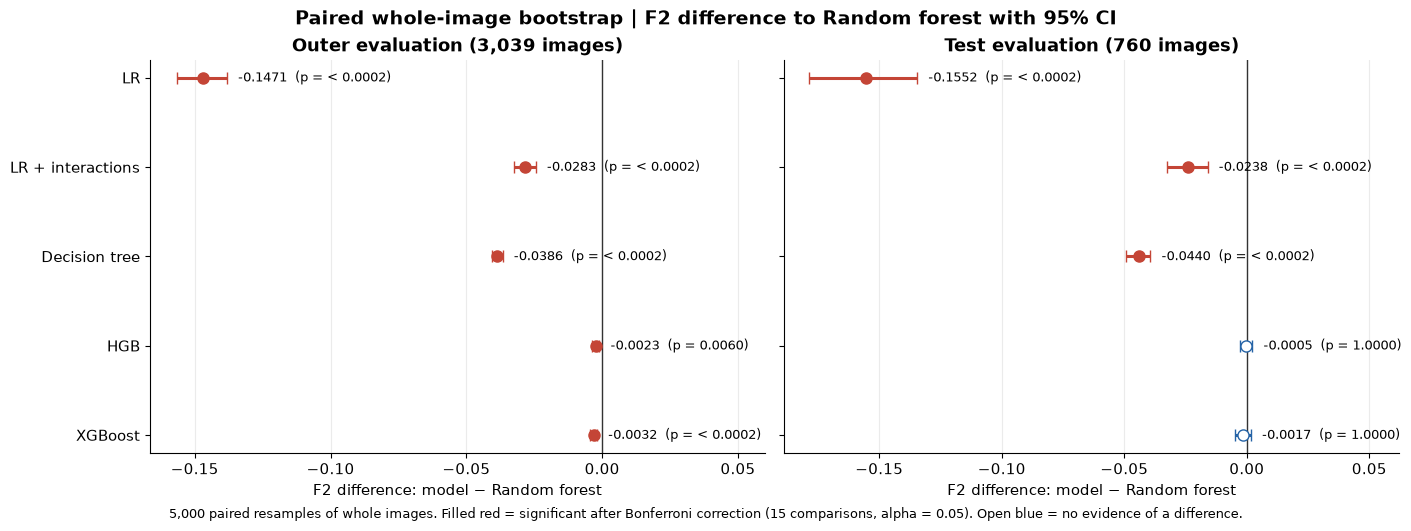

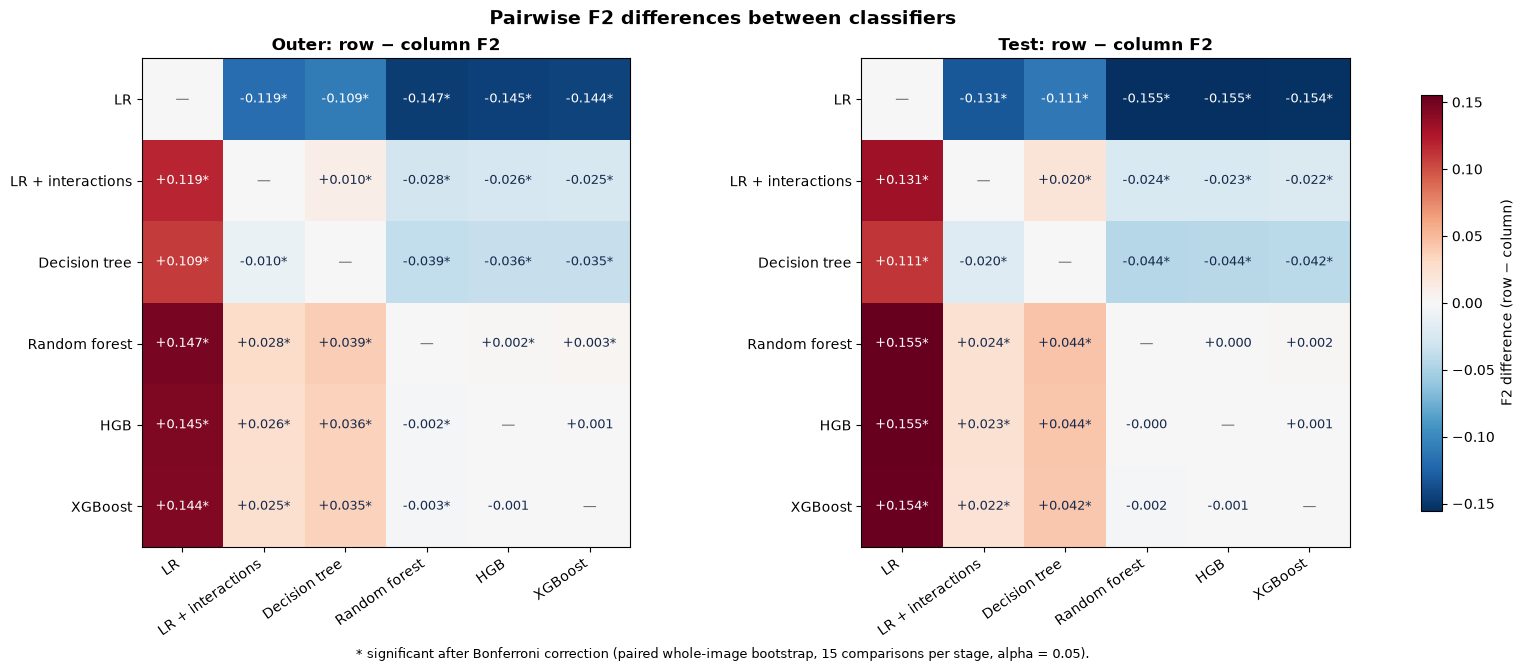

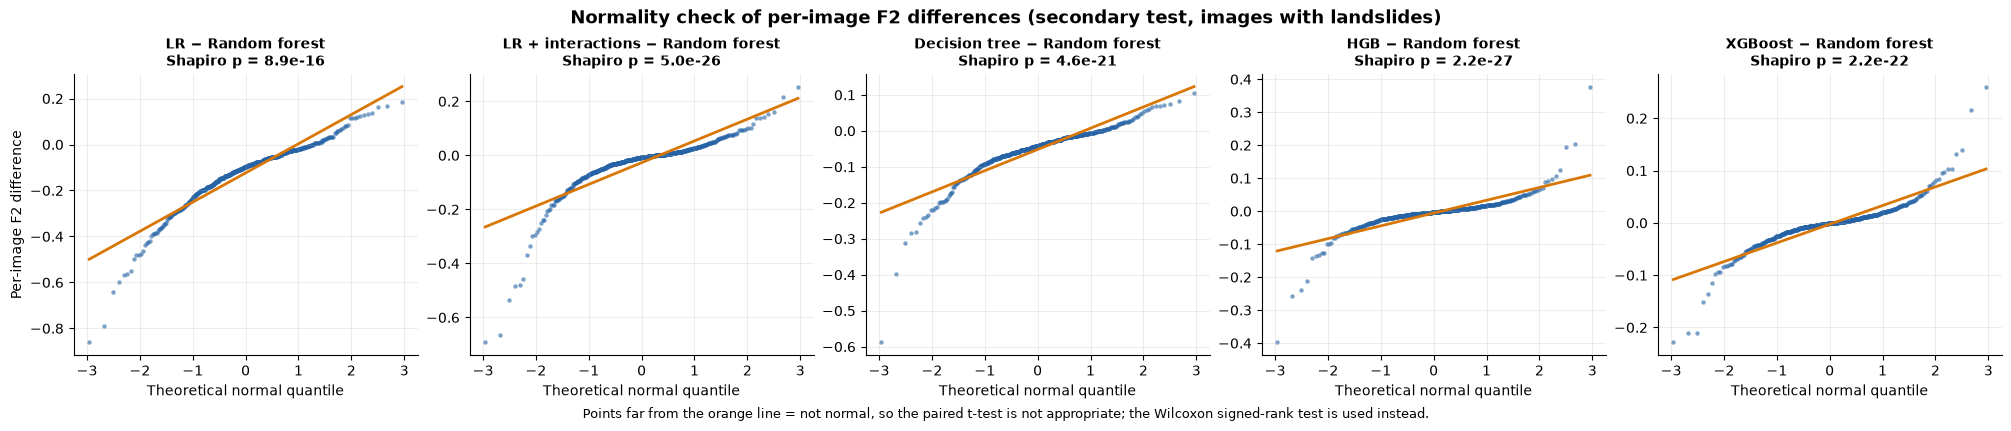


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\comparison


In [2]:
# Comparison — Step 2: statistical comparison of the six classifiers.
# Unit of analysis: image. Paired design (identical images for all models).
# H0: equal F2 (two-sided). alpha = 0.05 with Bonferroni correction for 15 pairs per stage.
# Uses the Step 1 per-image counts only. No model is retrained.

from itertools import combinations
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

CMP_BOOTSTRAP = 5000
CMP_ALPHA = 0.05
cmp_models = list(CMP_MODEL_ORDER)
n_models = len(cmp_models)
n_pairs = n_models * (n_models - 1) // 2
alpha_bonferroni = CMP_ALPHA / n_pairs

# Reference = best pooled F2 on the OUTER evaluation (chosen without the test set).
outer_ranking = (cmp_pooled[cmp_pooled["Stage"] == "Outer"]
                 .sort_values("F2", ascending=False))
reference_model = str(outer_ranking["Model"].iloc[0])
reference_index = cmp_models.index(reference_model)

print(f"Pairs per stage: {n_pairs} | Bonferroni alpha: {alpha_bonferroni:.5f}")
print(f"Reference model (best outer pooled F2): {reference_model}")


def cmp_stage_counts(stage):
    """Counts as an array (models, images, 4) with images in identical order for all models."""
    table = cmp_per_image[cmp_per_image["Stage"] == stage]
    image_ids = sorted(table["image_id"].unique(), key=int)
    counts = np.stack([
        table[table["Model"] == model].set_index("image_id")
        .loc[image_ids, COUNT_COLUMNS].to_numpy(dtype=np.int64)
        for model in cmp_models
    ])
    return image_ids, counts


def cmp_f2_from_sums(tn, fp, fn, tp):
    denominator = 5 * tp + 4 * fn + fp
    return np.divide(5 * tp, denominator,
                     out=np.zeros_like(denominator, dtype=float), where=denominator > 0)


def cmp_paired_bootstrap(counts, repetitions=CMP_BOOTSTRAP, seed=CMP_RANDOM_STATE):
    """Resample whole images; the SAME resample is applied to every model."""
    n_images = counts.shape[1]
    flat = counts.transpose(1, 0, 2).reshape(n_images, -1).astype(np.float64)
    rng = np.random.default_rng(seed)
    bootstrap_f2 = np.empty((repetitions, counts.shape[0]))
    for start in range(0, repetitions, 250):
        stop = min(start + 250, repetitions)
        weights = rng.multinomial(n_images, np.full(n_images, 1 / n_images),
                                  size=stop - start).astype(np.float64)
        sums = (weights @ flat).reshape(stop - start, counts.shape[0], 4)
        bootstrap_f2[start:stop] = cmp_f2_from_sums(*np.moveaxis(sums, -1, 0))
    return bootstrap_f2


def cmp_rank_biserial(differences):
    nonzero = differences[differences != 0]
    if len(nonzero) == 0:
        return 0.0
    ranks = stats.rankdata(np.abs(nonzero))
    return float((ranks[nonzero > 0].sum() - ranks[nonzero < 0].sum()) / ranks.sum())


cmp_results = {}
pair_rows = []

for stage in ("Outer", "Test"):
    image_ids, counts = cmp_stage_counts(stage)
    totals = counts.sum(axis=1).astype(float)
    observed_f2 = cmp_f2_from_sums(*totals.T)

    # Per-image F2 on images with reference landslides (identical set for all models).
    reference_pixels = counts[0, :, 3] + counts[0, :, 2]
    positive = reference_pixels > 0
    tn, fp, fn, tp = np.moveaxis(counts[:, positive, :].astype(float), -1, 0)
    per_image_f2 = 5 * tp / (5 * tp + 4 * fn + fp)

    print(f"\n{stage}: {len(image_ids)} images ({int(positive.sum())} with landslides) | "
          f"bootstrap {CMP_BOOTSTRAP:,} paired resamples...", flush=True)
    bootstrap_f2 = cmp_paired_bootstrap(counts)

    def pair_statistics(i, j):
        """Statistics for the difference model_i − model_j."""
        d_boot = bootstrap_f2[:, i] - bootstrap_f2[:, j]
        p_boot = min(1.0, 2 * min((d_boot <= 0).mean(), (d_boot >= 0).mean()))
        d_image = per_image_f2[i] - per_image_f2[j]
        shapiro_p = float(stats.shapiro(d_image).pvalue)
        if np.any(d_image != 0):
            wilcoxon_p = float(stats.wilcoxon(d_image, zero_method="wilcox",
                                              alternative="two-sided").pvalue)
        else:
            wilcoxon_p = 1.0
        low, high = np.quantile(d_boot, [0.025, 0.975])
        return {
            "Stage": stage,
            "Model_A": cmp_models[i], "Model_B": cmp_models[j],
            "F2_A": observed_f2[i], "F2_B": observed_f2[j],
            "F2_difference_A_minus_B": observed_f2[i] - observed_f2[j],
            "CI95_low": low, "CI95_high": high,
            "Bootstrap_p": p_boot,
            "Bootstrap_p_Bonferroni": min(1.0, p_boot * n_pairs),
            "P_A_better": float((d_boot > 0).mean()),
            "Per_image_mean_difference": float(d_image.mean()),
            "Per_image_median_difference": float(np.median(d_image)),
            "Shapiro_p": shapiro_p,
            "Wilcoxon_p": wilcoxon_p,
            "Wilcoxon_p_Bonferroni": min(1.0, wilcoxon_p * n_pairs),
            "Rank_biserial_r": cmp_rank_biserial(d_image),
        }

    for i, j in combinations(range(n_models), 2):
        pair_rows.append(pair_statistics(i, j))

    versus_reference = pd.DataFrame([
        pair_statistics(k, reference_index)
        for k in range(n_models) if k != reference_index
    ])
    versus_reference["Significant_bootstrap"] = (
        versus_reference["Bootstrap_p_Bonferroni"] < CMP_ALPHA
    )
    versus_reference["Significant_Wilcoxon"] = (
        versus_reference["Wilcoxon_p_Bonferroni"] < CMP_ALPHA
    )

    cmp_results[stage] = {
        "image_ids": image_ids, "observed_f2": observed_f2,
        "bootstrap_f2": bootstrap_f2, "per_image_f2": per_image_f2,
        "versus_reference": versus_reference,
    }

cmp_pairwise = pd.DataFrame(pair_rows)
cmp_pairwise["Significant_bootstrap"] = cmp_pairwise["Bootstrap_p_Bonferroni"] < CMP_ALPHA
cmp_pairwise["Significant_Wilcoxon"] = cmp_pairwise["Wilcoxon_p_Bonferroni"] < CMP_ALPHA

# ------------------------------------------------------------
# Display.
# ------------------------------------------------------------
def cmp_format_p(p):
    return f"< {1 / CMP_BOOTSTRAP:.4f}" if p == 0 else f"{p:.4f}"


for stage in ("Outer", "Test"):
    table = cmp_results[stage]["versus_reference"].copy()
    print(f"\n{stage.upper()} — EACH MODEL vs {reference_model} (difference = model − reference)")
    display_table = pd.DataFrame({
        "Model": table["Model_A"],
        "F2": table["F2_A"].map("{:.4f}".format),
        "Diff": table["F2_difference_A_minus_B"].map("{:+.4f}".format),
        "95% CI": [f"[{l:+.4f}, {h:+.4f}]" for l, h in zip(table["CI95_low"], table["CI95_high"])],
        "Boot p (Bonf.)": table["Bootstrap_p_Bonferroni"].map(cmp_format_p),
        "P(model better)": table["P_A_better"].map("{:.3f}".format),
        "Shapiro p": table["Shapiro_p"].map("{:.2e}".format),
        "Wilcoxon p (Bonf.)": table["Wilcoxon_p_Bonferroni"].map("{:.2e}".format),
        "r": table["Rank_biserial_r"].map("{:+.3f}".format),
    })
    print(display_table.to_string(index=False))

print(f"\nBootstrap p-values are two-sided percentile p-values; '< {1 / CMP_BOOTSTRAP:.4f}' means "
      "no resample crossed zero. Bonferroni-adjusted p < 0.05 means significant at the family level.")
print("Shapiro p < 0.05: per-image differences are not normal, so Wilcoxon replaces the paired t-test.")

cmp_pairwise.to_csv(CMP_DIR / "pairwise_statistical_comparison.csv", index=False)
for stage in ("Outer", "Test"):
    cmp_results[stage]["versus_reference"].to_csv(
        CMP_DIR / f"versus_reference_{stage.lower()}.csv", index=False
    )

# ------------------------------------------------------------
# Figure 1: forest plot of F2 differences vs. the reference model.
# ------------------------------------------------------------
others = [m for m in cmp_models if m != reference_model]

with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, constrained_layout=True)

    for ax, stage in zip(axes, ("Outer", "Test")):
        table = cmp_results[stage]["versus_reference"].set_index("Model_A").loc[others]
        y = np.arange(len(others))[::-1]
        for position, (model, row) in zip(y, table.iterrows()):
            significant = row["Significant_bootstrap"]
            colour = "#C44536" if significant else "#2563A6"
            ax.errorbar(row["F2_difference_A_minus_B"], position,
                        xerr=[[row["F2_difference_A_minus_B"] - row["CI95_low"]],
                              [row["CI95_high"] - row["F2_difference_A_minus_B"]]],
                        fmt="o", color=colour, ecolor=colour, elinewidth=2.2,
                        capsize=4, markersize=8,
                        markerfacecolor=colour if significant else "white")
            ax.annotate(f"{row['F2_difference_A_minus_B']:+.4f}  "
                        f"(p = {cmp_format_p(row['Bootstrap_p_Bonferroni'])})",
                        (row["CI95_high"], position), xytext=(8, 0),
                        textcoords="offset points", va="center", fontsize=9.5)
        ax.axvline(0, color="#333333", linewidth=1)
        ax.set_yticks(y, others)
        n_images = len(cmp_results[stage]["image_ids"])
        ax.set_title(f"{stage} evaluation ({n_images:,} images)", fontweight="bold")
        ax.set_xlabel(f"F2 difference: model − {reference_model}")
        ax.grid(axis="x", alpha=0.25)
        low = min(table["CI95_low"].min(), 0)
        ax.set_xlim(low - 0.01, max(table["CI95_high"].max(), 0) + 0.06)

    fig.suptitle(f"Paired whole-image bootstrap | F2 difference to {reference_model} "
                 f"with 95% CI", fontsize=14, fontweight="bold")
    fig.supxlabel(f"{CMP_BOOTSTRAP:,} paired resamples of whole images. Filled red = significant after "
                  f"Bonferroni correction ({n_pairs} comparisons, alpha = 0.05). "
                  "Open blue = no evidence of a difference.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_forest_plot_vs_reference.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# Figure 2: pairwise F2-difference heatmaps.
# ------------------------------------------------------------
with plt.rc_context({"font.size": 10}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.6), constrained_layout=True)
    limit = max(abs(cmp_pairwise["F2_difference_A_minus_B"]).max(), 1e-6)
    norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

    for ax, stage in zip(axes, ("Outer", "Test")):
        observed = cmp_results[stage]["observed_f2"]
        matrix = observed[:, None] - observed[None, :]
        stage_pairs = cmp_pairwise[cmp_pairwise["Stage"] == stage]
        significant = np.zeros((n_models, n_models), dtype=bool)
        for _, row in stage_pairs.iterrows():
            i, j = cmp_models.index(row["Model_A"]), cmp_models.index(row["Model_B"])
            significant[i, j] = significant[j, i] = row["Significant_bootstrap"]

        image = ax.imshow(matrix, cmap="RdBu_r", norm=norm)
        for i in range(n_models):
            for j in range(n_models):
                if i == j:
                    ax.text(j, i, "—", ha="center", va="center", color="#666666")
                    continue
                ax.text(j, i, f"{matrix[i, j]:+.3f}" + ("*" if significant[i, j] else ""),
                        ha="center", va="center", fontsize=9,
                        color="white" if abs(matrix[i, j]) > 0.6 * limit else "#172B4D")
        ax.set_xticks(range(n_models), cmp_models, rotation=35, ha="right")
        ax.set_yticks(range(n_models), cmp_models)
        ax.set_title(f"{stage}: row − column F2", fontweight="bold")

    fig.colorbar(image, ax=axes, shrink=0.85, label="F2 difference (row − column)")
    fig.suptitle("Pairwise F2 differences between classifiers", fontsize=14, fontweight="bold")
    fig.supxlabel("* significant after Bonferroni correction (paired whole-image bootstrap, "
                  f"{n_pairs} comparisons per stage, alpha = 0.05).", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_pairwise_heatmap.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# Figure 3: Q-Q plots of per-image F2 differences vs. the reference (test).
# ------------------------------------------------------------
with plt.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, len(others), figsize=(4 * len(others), 4.2),
                             constrained_layout=True)
    per_image_f2 = cmp_results["Test"]["per_image_f2"]
    table = cmp_results["Test"]["versus_reference"].set_index("Model_A")

    for ax, model in zip(axes, others):
        differences = per_image_f2[cmp_models.index(model)] - per_image_f2[reference_index]
        (theoretical, ordered), (slope, intercept, _) = stats.probplot(differences, dist="norm")
        ax.scatter(theoretical, ordered, s=10, alpha=0.6, color="#2563A6", linewidths=0)
        ax.plot(theoretical, slope * theoretical + intercept, color="#D97706", linewidth=2)
        ax.set_title(f"{model} − {reference_model}\nShapiro p = {table.loc[model, 'Shapiro_p']:.1e}",
                     fontsize=10, fontweight="bold")
        ax.set_xlabel("Theoretical normal quantile")
        ax.grid(alpha=0.22)
    axes[0].set_ylabel("Per-image F2 difference")

    fig.suptitle("Normality check of per-image F2 differences (secondary test, images with landslides)",
                 fontsize=13, fontweight="bold")
    fig.supxlabel("Points far from the orange line = not normal, so the paired t-test is not appropriate; "
                  "the Wilcoxon signed-rank test is used instead.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_qq_per_image_differences.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", CMP_DIR)

**Result — statistical comparison of the classifiers.**

*Design.* All six classifiers were evaluated on identical images, so the comparison is paired, with the image as the unit of analysis (pixels within an image are not independent). For each pair, H₀ states that both classifiers have equal F2 (two-sided, α = 0.05). With 15 pairwise comparisons per stage, a Bonferroni correction was applied (α = 0.0033). The reference model, random forest, was chosen as the best model on the outer evaluation, without using the test set. Two complementary tests were used: a paired whole-image bootstrap (5,000 resamples) of the pooled F2 difference, and a Wilcoxon signed-rank test of per-image F2 differences. Shapiro–Wilk tests rejected normality for every comparison (p < 10⁻¹⁵), and the Q-Q plots show heavy tails, so the paired t-test was not appropriate and the non-parametric Wilcoxon test was used instead.

*Findings.* The classifiers form four clearly separated performance groups:
1. **Ensemble models (random forest, HGB, XGBoost)**, the best group. On the secondary test their pooled F2 values differ by at most 0.002, and neither difference to random forest is significant (HGB −0.0005 [−0.0030, +0.0023]; XGBoost −0.0017 [−0.0050, +0.0017]; adjusted p = 1.0). HGB is better than random forest in 35% of bootstrap resamples, and XGBoost in 15%.
2. **Logistic regression with interactions**, significantly lower than random forest (−0.024 on the test set; −0.028 on the outer evaluation; p < 0.0002) but significantly better than the decision tree (+0.020 on the test set).
3. **Decision tree**, significantly lower than random forest (−0.044 on the test set).
4. **Logistic regression with raw features**, far below all other models (−0.155 on the test set); adding pairwise interactions improves it by +0.131 F2.

All differences between groups are significant in both evaluations and with both tests, with large effect sizes (rank-biserial r = −0.86 to −0.89 for LR and decision tree vs. random forest, and r = −0.33 for interaction LR).

*Statistical versus practical significance.* On the larger outer evaluation (3,039 images), random forest is statistically significantly better than HGB (+0.0023 F2, adjusted p = 0.006) and XGBoost (+0.0032, p < 0.0002). These differences are, however, very small in practical terms (below 0.5% of the F2 value) and are not confirmed on the test set, where the interval for each difference includes zero. This illustrates that with very large evaluation samples even negligible differences become "significant", so effect sizes must always be reported alongside p-values.

The per-image Wilcoxon test adds a further nuance: random forest achieves slightly higher F2 than HGB on typical individual images in both evaluations (r ≈ −0.19, a small effect), whereas the pooled pixel-level F2, which is dominated by large landslides, shows no meaningful difference. Random forest therefore appears marginally more robust on individual, often small, landslides, while the three ensemble models perform equivalently at the pixel level.

*Conclusion.* There is no evidence of a meaningful difference among the three ensemble models; "not significant" here means that differences larger than about ±0.003–0.005 F2 can be excluded, not that the models are identical. The choice among them can therefore be based on secondary criteria such as probability calibration (best for XGBoost), training time (much shorter for HGB and XGBoost than for random forest), and prediction speed (fastest for XGBoost).


OUTER — POOLED F2 BY LANDSLIDE COVERAGE (images: ≤ 1% = 610, 1–5% = 700, 5–20% = 438, > 20% = 37)
Coverage_group      ≤ 1%   1–5%  5–20%  > 20%
Model                                        
LR                0.3184 0.5757 0.7280 0.7863
LR + interactions 0.4706 0.6841 0.8023 0.8583
Decision tree     0.4523 0.6653 0.7920 0.8518
Random forest     0.5159 0.7076 0.8221 0.8763
HGB               0.5167 0.7019 0.8186 0.8763
XGBoost           0.5151 0.7023 0.8200 0.8746

TEST — POOLED F2 BY LANDSLIDE COVERAGE (images: ≤ 1% = 158, 1–5% = 183, 5–20% = 97, > 20% = 8)
Coverage_group      ≤ 1%   1–5%  5–20%  > 20%
Model                                        
LR                0.3133 0.5866 0.7111 0.8666
LR + interactions 0.4731 0.6842 0.7944 0.9087
Decision tree     0.4646 0.6569 0.7738 0.8702
Random forest     0.5171 0.7010 0.8164 0.9005
HGB               0.5106 0.7018 0.8136 0.8996
XGBoost           0.5123 0.7038 0.8131 0.9033

FALSE ALARMS ON IMAGES WITHOUT LANDSLIDES
                  FP_rate_

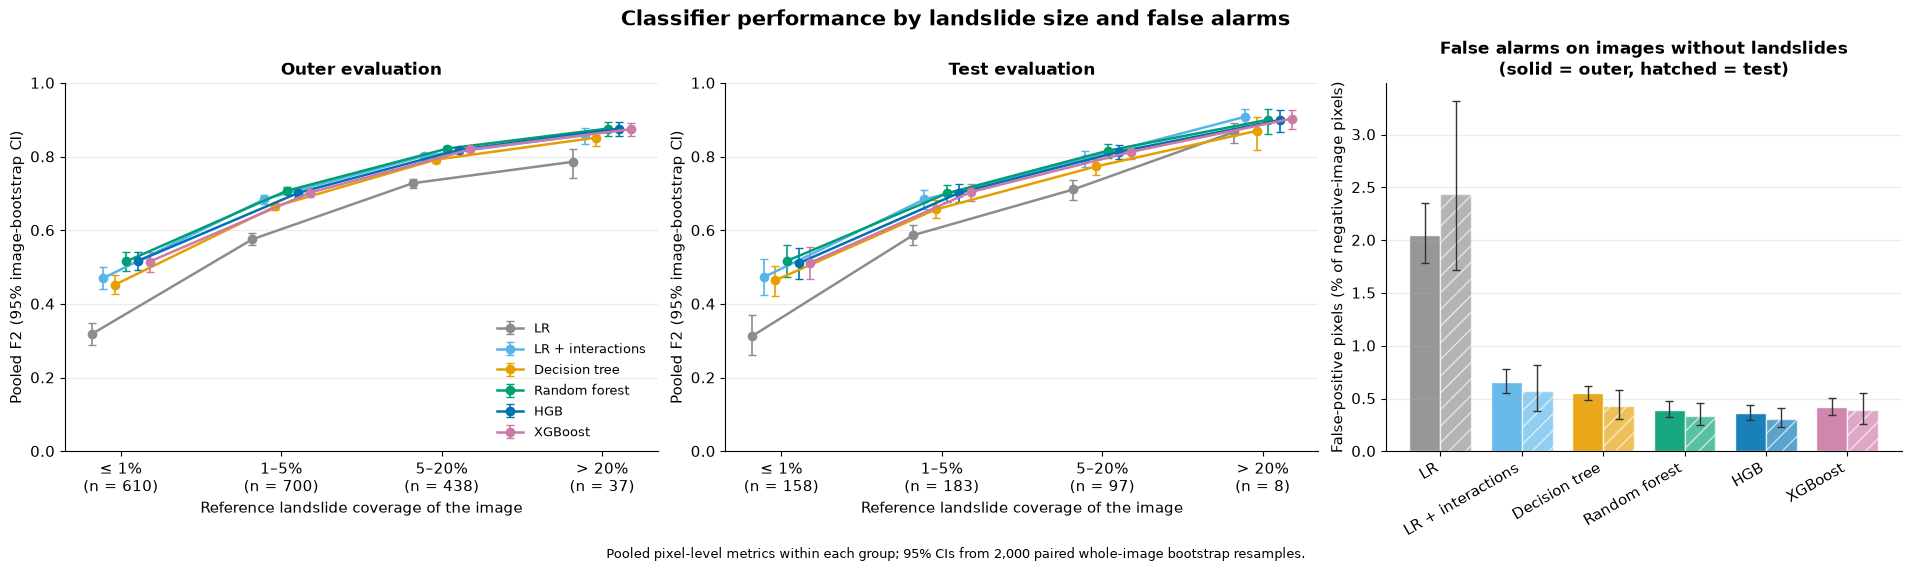

C:\Users\hadid\AppData\Local\Temp\ipykernel_9900\3396867984.py:185: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  violin = ax.violinplot(values, positions=[position], vert=False,
C:\Users\hadid\AppData\Local\Temp\ipykernel_9900\3396867984.py:195: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, positions=[position - 0.08], vert=False, widths=0.09,
C:\Users\hadid\AppData\Local\Temp\ipykernel_9900\3396867984.py:185: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  violin = ax.violinplot(values, positions=[position], vert=False,
C:\Users\hadid\AppData\Local\Temp\ipykernel_9900\3396867984.py:195: MatplotlibDeprecationWarning: vert: bool was dep

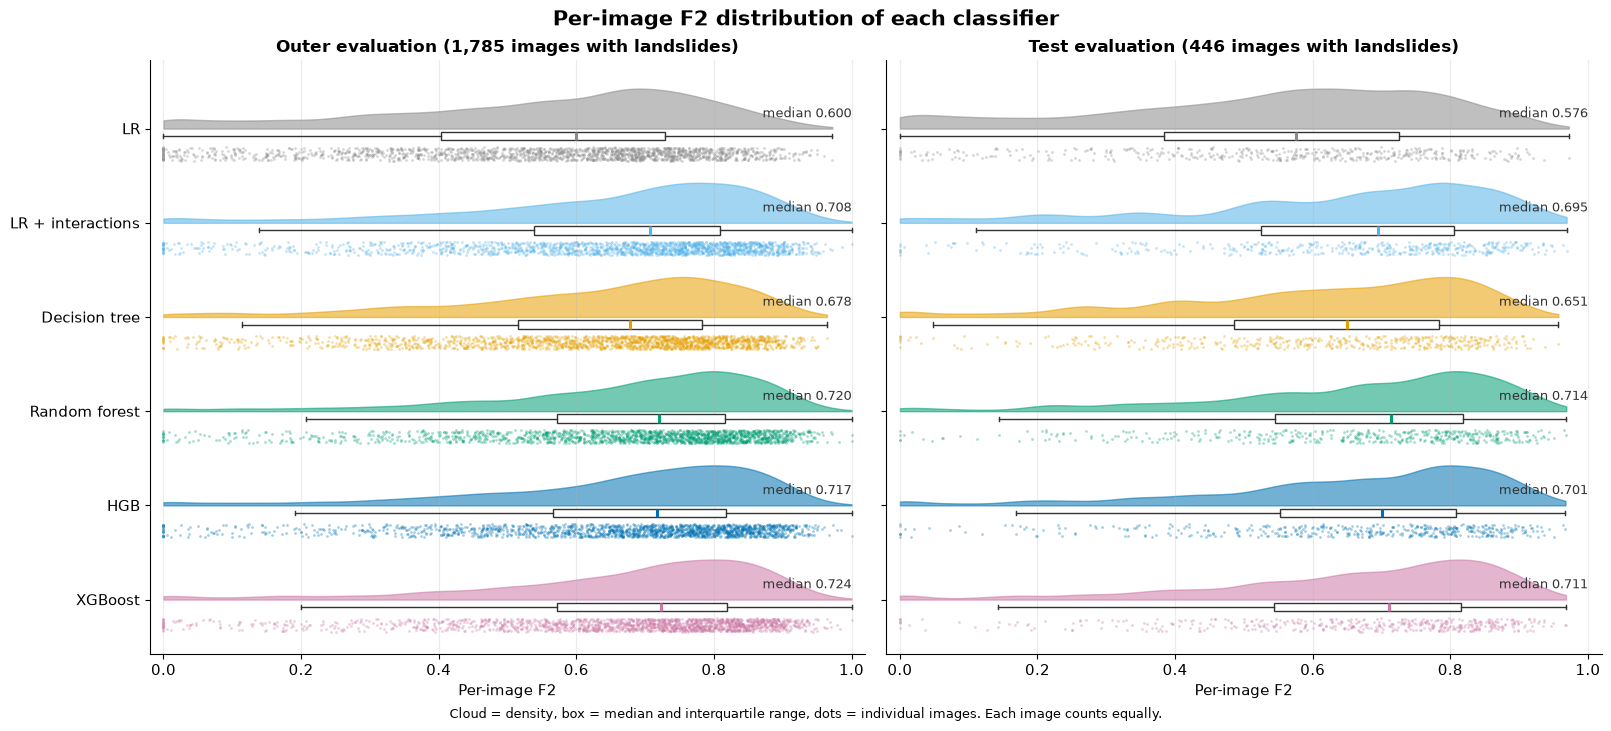


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\comparison


In [3]:
# Comparison — Step 3: performance by landslide size and per-image F2 distributions.
# Uses the Step 1 per-image counts only. No model is retrained.

CMP_COVERAGE_BINS = [0, 1, 5, 20, 100]
CMP_COVERAGE_LABELS = ["≤ 1%", "1–5%", "5–20%", "> 20%"]
CMP_GROUP_BOOTSTRAP = 2000

# Okabe–Ito colour-blind-safe palette, fixed per model for all comparison figures.
CMP_COLORS = {
    "LR": "#8C8C8C",
    "LR + interactions": "#56B4E9",
    "Decision tree": "#E69F00",
    "Random forest": "#009E73",
    "HGB": "#0072B2",
    "XGBoost": "#CC79A7",
}


def cmp_bootstrap_sums(counts, repetitions, seed=CMP_RANDOM_STATE):
    """Paired whole-image bootstrap of summed counts: returns (repetitions, models, 4)."""
    n_images = counts.shape[1]
    flat = counts.transpose(1, 0, 2).reshape(n_images, -1).astype(np.float64)
    rng = np.random.default_rng(seed)
    sums = np.empty((repetitions, counts.shape[0], 4))
    for start in range(0, repetitions, 250):
        stop = min(start + 250, repetitions)
        weights = rng.multinomial(n_images, np.full(n_images, 1 / n_images),
                                  size=stop - start).astype(np.float64)
        sums[start:stop] = (weights @ flat).reshape(stop - start, counts.shape[0], 4)
    return sums


def cmp_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)
    return np.divide(numerator, denominator, out=np.full_like(numerator, np.nan),
                     where=denominator > 0)


group_rows = []
negative_rows = []
cmp_size_results = {}

for stage in ("Outer", "Test"):
    image_ids, counts = cmp_stage_counts(stage)
    reference_pixels = counts[0, :, 3] + counts[0, :, 2]
    positive = reference_pixels > 0
    coverage = 100 * reference_pixels / CMP_PIXELS_PER_IMAGE
    groups = pd.cut(coverage, bins=CMP_COVERAGE_BINS, labels=CMP_COVERAGE_LABELS,
                    right=True, include_lowest=False)

    # Positive images by coverage group.
    for label in CMP_COVERAGE_LABELS:
        mask = positive & (groups == label)
        group_counts = counts[:, mask, :]
        totals = group_counts.sum(axis=1).astype(float)
        tn, fp, fn, tp = totals.T
        f2 = cmp_ratio(5 * tp, 5 * tp + 4 * fn + fp)
        boot = cmp_bootstrap_sums(group_counts, CMP_GROUP_BOOTSTRAP)
        b_tn, b_fp, b_fn, b_tp = np.moveaxis(boot, -1, 0)
        boot_f2 = cmp_ratio(5 * b_tp, 5 * b_tp + 4 * b_fn + b_fp)
        low, high = np.nanquantile(boot_f2, [0.025, 0.975], axis=0)

        for m, model in enumerate(cmp_models):
            group_rows.append({
                "Stage": stage, "Coverage_group": label, "Images": int(mask.sum()),
                "Model": model, "F2": f2[m], "F2_CI_low": low[m], "F2_CI_high": high[m],
                "Precision": cmp_ratio(tp[m], tp[m] + fp[m]),
                "Recall": cmp_ratio(tp[m], tp[m] + fn[m]),
            })

    # Negative images: false-positive pixel rate and share of images without any false alarm.
    negative_counts = counts[:, ~positive, :]
    totals = negative_counts.sum(axis=1).astype(float)
    fp_rate = 100 * cmp_ratio(totals[:, 1], totals[:, 0] + totals[:, 1])
    boot = cmp_bootstrap_sums(negative_counts, CMP_GROUP_BOOTSTRAP)
    boot_rate = 100 * cmp_ratio(boot[..., 1], boot[..., 0] + boot[..., 1])
    low, high = np.quantile(boot_rate, [0.025, 0.975], axis=0)
    zero_fp_share = 100 * (negative_counts[:, :, 1] == 0).mean(axis=1)
    median_fp = np.median(negative_counts[:, :, 1], axis=1)

    for m, model in enumerate(cmp_models):
        negative_rows.append({
            "Stage": stage, "Model": model, "Negative_images": int((~positive).sum()),
            "FP_rate_percent": fp_rate[m], "FP_rate_CI_low": low[m], "FP_rate_CI_high": high[m],
            "Images_without_false_alarm_percent": zero_fp_share[m],
            "Median_FP_pixels": median_fp[m],
        })

    # Per-image F2 for the raincloud plot.
    tn, fp, fn, tp = np.moveaxis(counts[:, positive, :].astype(float), -1, 0)
    cmp_size_results[stage] = {"per_image_f2": 5 * tp / (5 * tp + 4 * fn + fp)}

cmp_size_table = pd.DataFrame(group_rows)
cmp_negative_table = pd.DataFrame(negative_rows)
cmp_size_table.to_csv(CMP_DIR / "performance_by_coverage_group.csv", index=False)
cmp_negative_table.to_csv(CMP_DIR / "false_alarms_on_negative_images.csv", index=False)

for stage in ("Outer", "Test"):
    table = cmp_size_table[cmp_size_table["Stage"] == stage]
    images = table.groupby("Coverage_group", sort=False)["Images"].first()
    print(f"\n{stage.upper()} — POOLED F2 BY LANDSLIDE COVERAGE "
          f"(images: {', '.join(f'{k} = {v}' for k, v in images.items())})")
    print(table.pivot(index="Model", columns="Coverage_group", values="F2")
          .reindex(index=cmp_models, columns=CMP_COVERAGE_LABELS)
          .to_string(float_format=lambda x: f"{x:.4f}"))

print("\nFALSE ALARMS ON IMAGES WITHOUT LANDSLIDES")
print(cmp_negative_table.pivot(index="Model", columns="Stage",
                               values=["FP_rate_percent", "Images_without_false_alarm_percent",
                                       "Median_FP_pixels"])
      .reindex(cmp_models).to_string(float_format=lambda x: f"{x:.3f}"))

# ------------------------------------------------------------
# Figure 1: performance by landslide size and false alarms on negative images.
# ------------------------------------------------------------
offsets = np.linspace(-0.18, 0.18, len(cmp_models))

with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), constrained_layout=True,
                             gridspec_kw={"width_ratios": [1.15, 1.15, 1]})

    for ax, stage in zip(axes[:2], ("Outer", "Test")):
        table = cmp_size_table[cmp_size_table["Stage"] == stage]
        x = np.arange(len(CMP_COVERAGE_LABELS))
        for offset, model in zip(offsets, cmp_models):
            rows = table[table["Model"] == model].set_index("Coverage_group").loc[CMP_COVERAGE_LABELS]
            ax.errorbar(x + offset, rows["F2"],
                        yerr=[rows["F2"] - rows["F2_CI_low"], rows["F2_CI_high"] - rows["F2"]],
                        fmt="-o", color=CMP_COLORS[model], markersize=6, linewidth=1.8,
                        capsize=3, elinewidth=1.2, label=model)
        images = table.groupby("Coverage_group", sort=False)["Images"].first()
        ax.set_xticks(x, [f"{label}\n(n = {images[label]})" for label in CMP_COVERAGE_LABELS])
        ax.set_xlabel("Reference landslide coverage of the image")
        ax.set_ylabel("Pooled F2 (95% image-bootstrap CI)")
        ax.set_ylim(0, 1)
        ax.set_title(f"{stage} evaluation", fontweight="bold")
        ax.grid(axis="y", alpha=0.25)
    axes[0].legend(frameon=False, loc="lower right", fontsize=9.5)

    ax = axes[2]
    width = 0.38
    x = np.arange(len(cmp_models))
    for shift, stage, hatch in ((-width / 2, "Outer", None), (width / 2, "Test", "//")):
        rows = cmp_negative_table[cmp_negative_table["Stage"] == stage].set_index("Model").loc[cmp_models]
        ax.bar(x + shift, rows["FP_rate_percent"], width=width,
               color=[CMP_COLORS[m] for m in cmp_models], edgecolor="white",
               hatch=hatch, alpha=0.9 if stage == "Outer" else 0.65)
        ax.errorbar(x + shift, rows["FP_rate_percent"],
                    yerr=[rows["FP_rate_percent"] - rows["FP_rate_CI_low"],
                          rows["FP_rate_CI_high"] - rows["FP_rate_percent"]],
                    fmt="none", ecolor="#333333", capsize=3, linewidth=1)
    ax.set_xticks(x, cmp_models, rotation=30, ha="right")
    ax.set_ylabel("False-positive pixels (% of negative-image pixels)")
    ax.set_title("False alarms on images without landslides\n(solid = outer, hatched = test)",
                 fontweight="bold")
    ax.grid(axis="y", alpha=0.25)

    fig.suptitle("Classifier performance by landslide size and false alarms",
                 fontsize=15, fontweight="bold")
    fig.supxlabel(f"Pooled pixel-level metrics within each group; 95% CIs from "
                  f"{CMP_GROUP_BOOTSTRAP:,} paired whole-image bootstrap resamples.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_performance_by_size.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# Figure 2: raincloud plot of per-image F2 (images with landslides).
# ------------------------------------------------------------
rng_plot = np.random.default_rng(CMP_RANDOM_STATE)

with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.2), sharey=True, constrained_layout=True)

    for ax, stage in zip(axes, ("Outer", "Test")):
        per_image_f2 = cmp_size_results[stage]["per_image_f2"]
        positions = np.arange(len(cmp_models))[::-1].astype(float)

        for position, model in zip(positions, cmp_models):
            values = per_image_f2[cmp_models.index(model)]
            colour = CMP_COLORS[model]

            # Half-violin (cloud) above the line.
            violin = ax.violinplot(values, positions=[position], vert=False,
                                   widths=0.85, showextrema=False, bw_method=0.15)
            for body in violin["bodies"]:
                vertices = body.get_paths()[0].vertices
                vertices[:, 1] = np.clip(vertices[:, 1], position, np.inf)
                body.set_facecolor(colour)
                body.set_edgecolor(colour)
                body.set_alpha(0.55)

            # Box plot on the line.
            ax.boxplot(values, positions=[position - 0.08], vert=False, widths=0.09,
                       showfliers=False, patch_artist=True,
                       boxprops={"facecolor": "white", "edgecolor": "#333333"},
                       medianprops={"color": colour, "linewidth": 2.2},
                       whiskerprops={"color": "#333333"}, capprops={"color": "#333333"})

            # Individual images (rain) below the line.
            jitter = rng_plot.uniform(-0.07, 0.07, len(values))
            ax.scatter(values, position - 0.27 + jitter, s=4, alpha=0.35, color=colour,
                       linewidths=0, rasterized=True)

            ax.annotate(f"median {np.median(values):.3f}", (1.0, position + 0.12),
                        ha="right", fontsize=9, color="#333333")

        ax.set_yticks(positions, cmp_models)
        ax.set_xlim(-0.02, 1.02)
        ax.set_xlabel("Per-image F2")
        n_images = per_image_f2.shape[1]
        ax.set_title(f"{stage} evaluation ({n_images:,} images with landslides)", fontweight="bold")
        ax.grid(axis="x", alpha=0.25)

    fig.suptitle("Per-image F2 distribution of each classifier", fontsize=15, fontweight="bold")
    fig.supxlabel("Cloud = density, box = median and interquartile range, dots = individual images. "
                  "Each image counts equally.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_raincloud_per_image_f2.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", CMP_DIR)

**Result — performance by landslide size and false alarms.** Detection performance depends strongly on how much of an image is covered by landslides, for all classifiers. On the outer evaluation, pooled F2 rises from about 0.52 for the best models in images with ≤ 1% landslide coverage (610 images) to about 0.71 (1–5%), 0.82 (5–20%), and 0.88 (> 20%). Small landslides therefore remain the main difficulty, even for the best classifiers.

The differences between classifiers are largest for small landslides and shrink as coverage increases. In the ≤ 1% group, the three ensemble models (random forest, HGB, XGBoost: F2 ≈ 0.52) clearly outperform interaction LR (0.47), the decision tree (0.45), and raw-feature LR (0.32). In images with more than 20% coverage, all models except raw-feature LR reach similar F2 (0.85–0.88). The test results follow the same pattern; the > 20% group contains only 8 test images, so its intervals are wide. The advantage of the ensemble models therefore comes mainly from better detection of small landslides.

On images without landslides, raw-feature LR produces by far the most false alarms (about 2.0–2.4% of pixels), five to seven times more than the ensemble models. HGB has the lowest false-positive rate (0.36% outer, 0.31% test), followed by random forest (0.39% / 0.34%) and XGBoost (0.42% / 0.39%). XGBoost leaves the largest share of negative images completely free of false alarms (34% / 35%), and the ensemble models have a median of only 5–9 false-positive pixels per negative image, compared with 15–27 for the decision tree.

The per-image F2 distributions confirm the ranking: median per-image F2 on the test set is 0.714 (random forest), 0.711 (XGBoost), 0.701 (HGB), 0.695 (interaction LR), 0.651 (decision tree), and 0.576 (raw-feature LR). All distributions are left-skewed with long tails towards zero, caused by images with very small landslides that are partly or completely missed. Interaction LR reaches a median close to the ensembles, so its lower pooled F2 is driven mainly by these difficult small-landslide images.

Loading saved test probabilities...
  LR: scores loaded and aligned.
  LR + interactions: scores loaded and aligned.
  Decision tree: scores loaded and aligned.
  Random forest: scores loaded and aligned.
  HGB: scores loaded and aligned.
  XGBoost: scores loaded and aligned.
  LR: recomputed counts match the saved results (0 pixel differences from float rounding).
  LR + interactions: recomputed counts match the saved results (0 pixel differences from float rounding).
  Decision tree: recomputed counts match the saved results (0 pixel differences from float rounding).
  Random forest: recomputed counts match the saved results (0 pixel differences from float rounding).
  HGB: recomputed counts match the saved results (0 pixel differences from float rounding).
  XGBoost: recomputed counts match the saved results (0 pixel differences from float rounding).

Calculating exact average precision and PR curves...

EXACT AVERAGE PRECISION (secondary test)
  LR                 AP = 0.5041 | ope

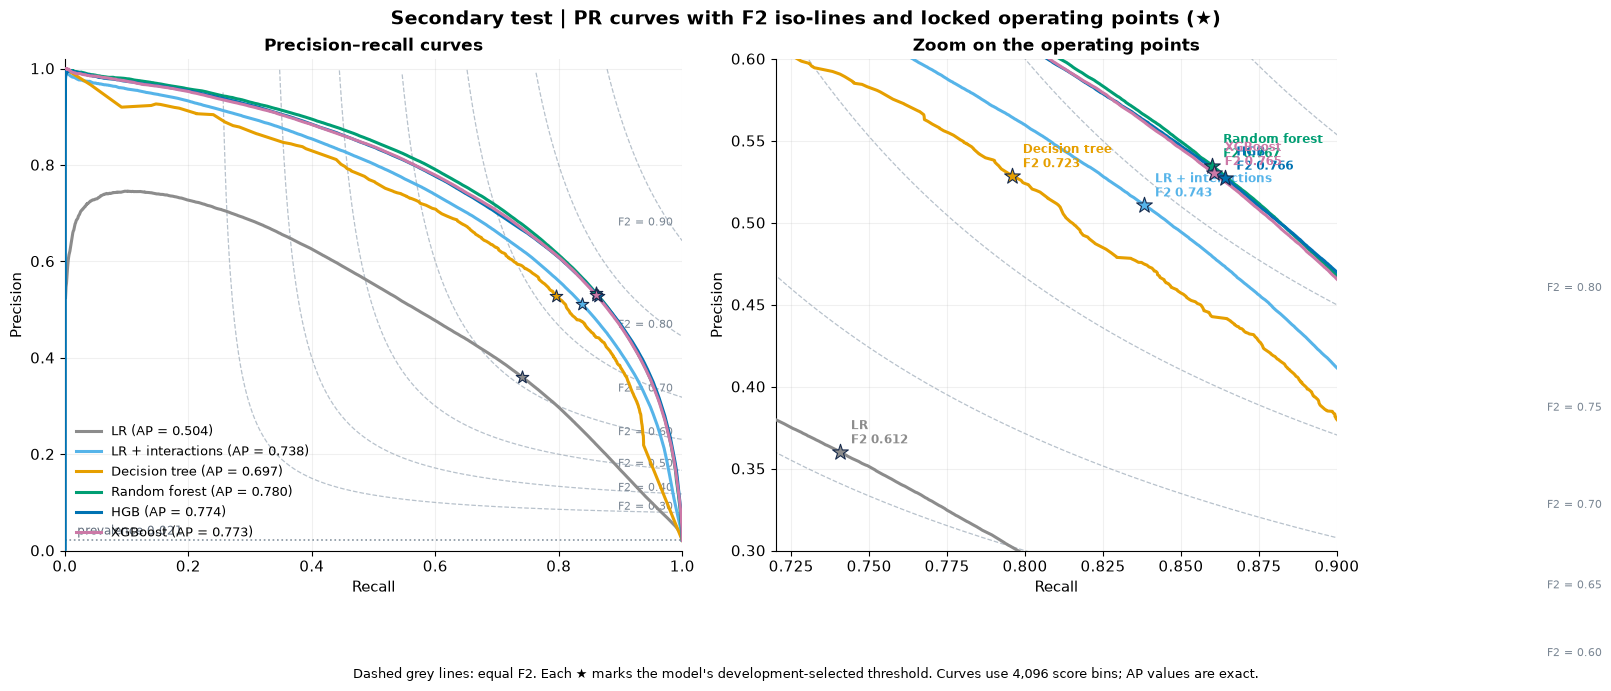


MODEL CONSENSUS ON THE SECONDARY TEST (12,451,840 pixels)
 Models_predicting_landslide  Landslide_pixels  Landslide_pixels_percent  Non_landslide_pixels
                           0             21271                      8.02              11668945
                           1              8095                      3.05                255809
                           2              6478                      2.44                 56610
                           3              7485                      2.82                 37063
                           4             14326                      5.40                 41754
                           5             31132                     11.73                 49000
                           6            176594                     66.54                 77278

Landslide pixels detected by all six models: 66.5%
Landslide pixels missed by all six models:   8.0%
Of all landslide pixels missed by at least one model, 24.0% are missed by every

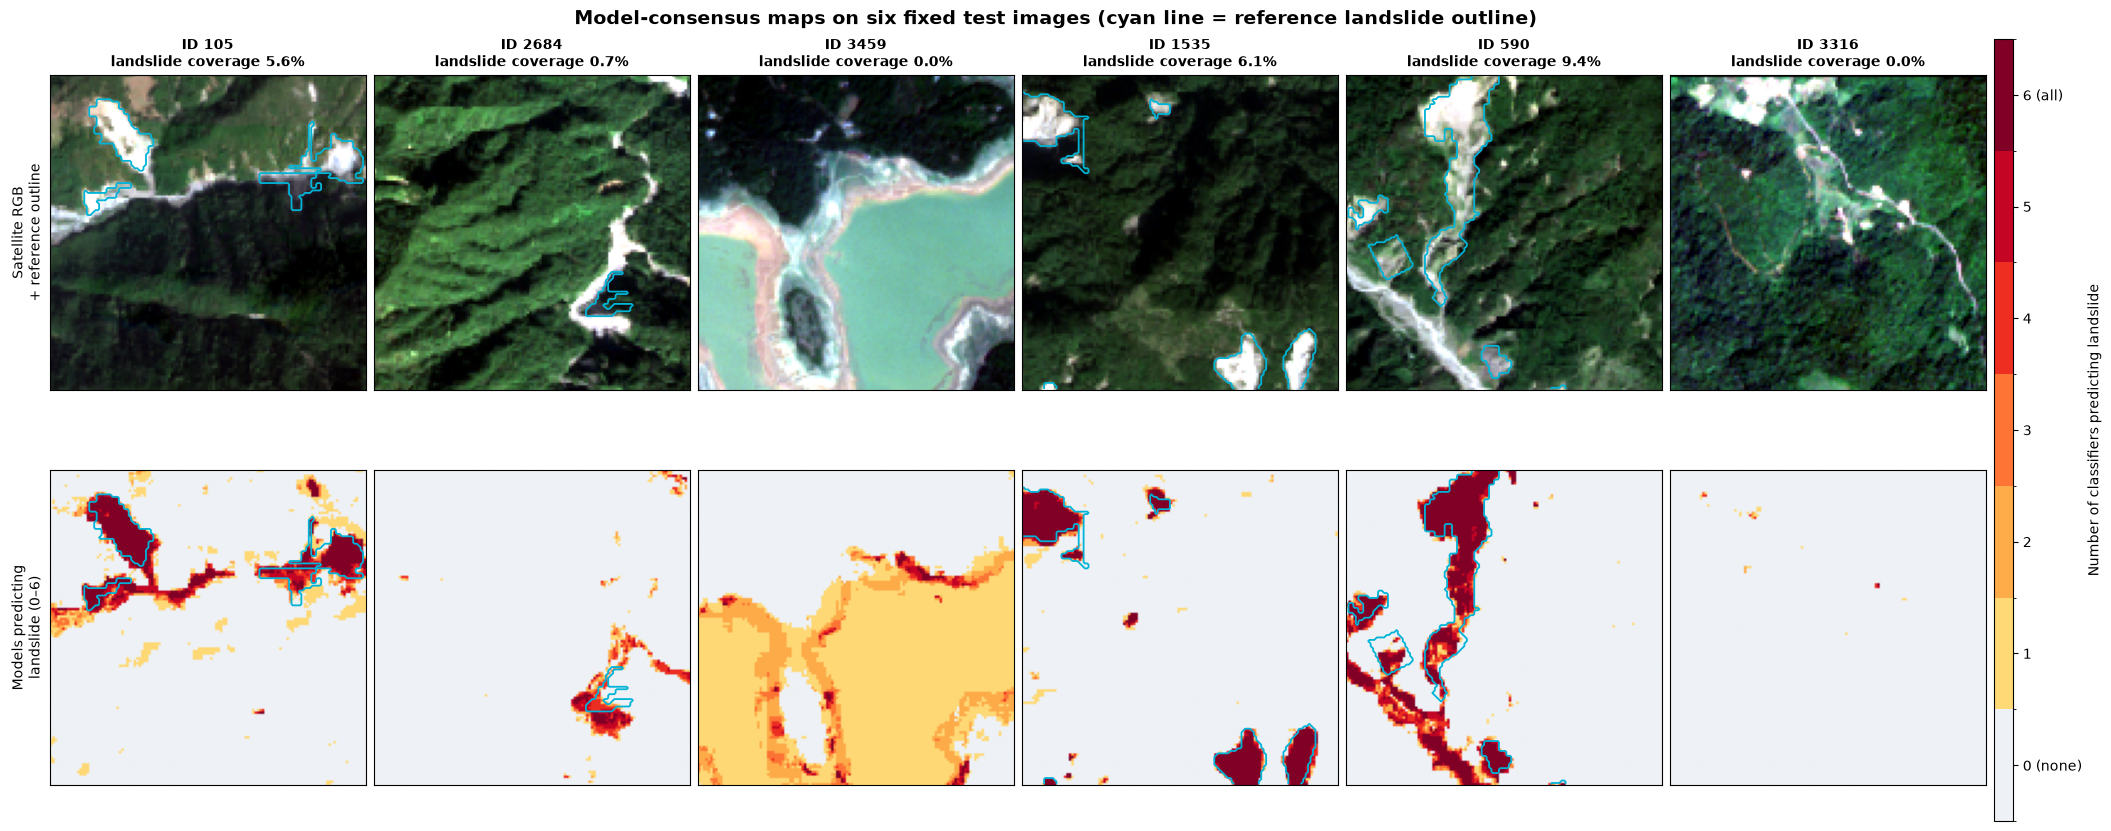


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\comparison


In [4]:
# Comparison — Step 4: PR curves with F2 iso-lines and model-consensus maps (secondary test).
# Loads saved test probabilities, aligns them strictly by image ID, and verifies them
# against the saved per-image counts. No model is retrained.

import h5py
from sklearn.metrics import average_precision_score
from matplotlib.colors import ListedColormap, BoundaryNorm

PIX = CMP_PIXELS_PER_IMAGE
cmp_test_order = sorted(cmp_test_ids, key=int)
cmp_test_position = {image_id: p for p, image_id in enumerate(cmp_test_order)}
n_test = len(cmp_test_order)

cmp_test_scores = np.empty((n_models, n_test, PIX), dtype=np.float32)
cmp_test_labels = np.empty((n_test, PIX), dtype=np.uint8)
cmp_labels_filled = False


def cmp_place(model, ordered_ids, scores, labels):
    """Store one model's scores in the common numeric image order and check labels."""
    global cmp_labels_filled
    ordered_ids = [str(i).strip() for i in ordered_ids]
    assert len(ordered_ids) == n_test and set(ordered_ids) == cmp_test_ids, f"{model}: IDs differ."
    scores = np.asarray(scores).reshape(n_test, PIX)
    labels = np.asarray(labels).reshape(n_test, PIX).astype(np.uint8)
    positions = np.array([cmp_test_position[i] for i in ordered_ids])
    cmp_test_scores[cmp_models.index(model), positions] = scores
    if not cmp_labels_filled:
        cmp_test_labels[positions] = labels
        cmp_labels_filled = True
    else:
        assert np.array_equal(cmp_test_labels[positions], labels), f"{model}: labels differ."
    print(f"  {model}: scores loaded and aligned.", flush=True)


print("Loading saved test probabilities...", flush=True)

# --- Logistic regression (both variants): order from the per-image Start/Stop records.
lr_arrays = cmp_lr_folder / "arrays"
lr_labels = np.load(lr_arrays / "lr_test_y.npy", mmap_mode="r")
lr_table = cmp_get(cmp_lr_tables, "lr_test_patch_results", "LR").sort_values("Start")
assert np.array_equal(lr_table["Start"].to_numpy(), np.arange(n_test) * PIX)
lr_order = lr_table["sample_id"].astype(str).tolist()

cmp_place("LR", lr_order, np.load(lr_arrays / "lr_test_probability.npy", mmap_mode="r"), lr_labels)

lr_int_table = cmp_get(cmp_lr_tables, "lr_interaction_secondary_test_patch_results",
                       "LR + interactions")
if "Start" in lr_int_table.columns:
    lr_int_table = lr_int_table.sort_values("Start")
    assert np.array_equal(lr_int_table["Start"].to_numpy(), np.arange(n_test) * PIX)
    lr_int_order = lr_int_table["sample_id"].astype(str).tolist()
else:
    lr_int_order = lr_order
cmp_place("LR + interactions", lr_int_order,
          np.load(lr_arrays / "lr_interaction_secondary_test_probability.npy", mmap_mode="r"),
          lr_labels)

# --- Decision tree.
dt_holdout = cmp_get(joblib.load(cmp_dt_folder / "final_model_and_holdout.joblib"),
                     "dt_final_holdout_evaluation", "Decision tree")
cmp_place("Decision tree", dt_holdout["patch_ids"], dt_holdout["probability"], dt_holdout["y"])
del dt_holdout

# --- Random forest.
rf_evaluation = joblib.load(cmp_rf_paths["test_evaluation"])
cmp_place("Random forest", rf_evaluation["metadata"]["ordered_image_ids"],
          np.load(rf_evaluation["scores_path"], mmap_mode="r"),
          np.load(rf_evaluation["labels_path"], mmap_mode="r"))
del rf_evaluation

# --- HGB and XGBoost.
for model, folder, prefix in (("HGB", "hist_gradient_boosting", "hgb"),
                              ("XGBoost", "xgboost", "xgb")):
    bundle = joblib.load(CMP_ARTIFACTS / "classifier_comparison" / folder
                         / f"{prefix}_comparison_bundle.joblib")
    cmp_place(model, bundle["test_ordered_image_ids"],
              np.load(bundle["test_scores_path"], mmap_mode="r"),
              np.load(bundle["test_labels_path"], mmap_mode="r"))
    del bundle

# ------------------------------------------------------------
# Verification: scores + locked thresholds reproduce the saved per-image counts.
# ------------------------------------------------------------
test_counts_saved = cmp_per_image[cmp_per_image["Stage"] == "Test"]
positive_label = cmp_test_labels == 1

for m, model in enumerate(cmp_models):
    predicted = cmp_test_scores[m].astype(np.float64) >= CMP_THRESHOLDS[model]
    recomputed = pd.DataFrame({
        "image_id": cmp_test_order,
        "TN": np.count_nonzero(~predicted & ~positive_label, axis=1),
        "FP": np.count_nonzero(predicted & ~positive_label, axis=1),
        "FN": np.count_nonzero(~predicted & positive_label, axis=1),
        "TP": np.count_nonzero(predicted & positive_label, axis=1),
    }).set_index("image_id")
    saved = (test_counts_saved[test_counts_saved["Model"] == model]
             .set_index("image_id").loc[cmp_test_order, COUNT_COLUMNS])
    mismatched_pixels = int(np.abs(recomputed[COUNT_COLUMNS].to_numpy()
                                   - saved.to_numpy()).sum() // 2)
    assert mismatched_pixels <= 10, (
        f"{model}: {mismatched_pixels} pixels differ from the saved counts — check alignment."
    )
    print(f"  {model}: recomputed counts match the saved results "
          f"({mismatched_pixels} pixel differences from float rounding).")

# ------------------------------------------------------------
# Exact average precision and binned PR curves.
# ------------------------------------------------------------
print("\nCalculating exact average precision and PR curves...", flush=True)
labels_flat = cmp_test_labels.reshape(-1)
total_positive = int(labels_flat.sum())
total_negative = labels_flat.size - total_positive
prevalence = total_positive / labels_flat.size

score_bins = 4096
cmp_pr_curves = {}
cmp_average_precision = {}
for m, model in enumerate(cmp_models):
    scores_flat = cmp_test_scores[m].reshape(-1).astype(np.float64)
    cmp_average_precision[model] = float(average_precision_score(labels_flat, scores_flat))
    bins = np.minimum((scores_flat * score_bins).astype(np.int32), score_bins - 1)
    positive_hist = np.bincount(bins[labels_flat == 1], minlength=score_bins)
    negative_hist = np.bincount(bins[labels_flat == 0], minlength=score_bins)
    tp_curve = np.cumsum(positive_hist[::-1]).astype(float)
    fp_curve = np.cumsum(negative_hist[::-1]).astype(float)
    cmp_pr_curves[model] = (tp_curve / total_positive,
                            np.divide(tp_curve, tp_curve + fp_curve,
                                      out=np.ones_like(tp_curve), where=(tp_curve + fp_curve) > 0))
    del scores_flat, bins

operating = (cmp_pooled[cmp_pooled["Stage"] == "Test"].set_index("Model")
             .loc[cmp_models, ["Precision", "Recall", "F2"]])

print("\nEXACT AVERAGE PRECISION (secondary test)")
for model in cmp_models:
    print(f"  {model:<18} AP = {cmp_average_precision[model]:.4f} | operating point: "
          f"recall {operating.loc[model, 'Recall']:.3f}, precision {operating.loc[model, 'Precision']:.3f}, "
          f"F2 {operating.loc[model, 'F2']:.4f}")


def cmp_draw_f2_isolines(ax, levels, label_recall=0.985):
    recall_grid = np.linspace(0.001, 1, 600)
    for level in levels:
        valid = recall_grid > 0.8 * level + 1e-6
        r = recall_grid[valid]
        p = level * r / (5 * r - 4 * level)
        keep = (p > 0) & (p <= 1)
        ax.plot(r[keep], p[keep], color="#B8C2CC", linewidth=0.9, linestyle="--", zorder=1)
        if label_recall > 0.8 * level:
            p_label = level * label_recall / (5 * label_recall - 4 * level)
            if 0 < p_label < 1:
                ax.text(label_recall, p_label, f"F2 = {level:.2f}", fontsize=8,
                        color="#7B8794", ha="right", va="bottom")


# ------------------------------------------------------------
# Figure 1: PR curves with F2 iso-lines and operating points.
# ------------------------------------------------------------
with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.8), constrained_layout=True,
                             gridspec_kw={"width_ratios": [1.1, 1]})

    for ax, zoom in zip(axes, (False, True)):
        cmp_draw_f2_isolines(ax, [0.6, 0.65, 0.7, 0.75, 0.8] if zoom
                             else [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
        for model in cmp_models:
            recall_curve, precision_curve = cmp_pr_curves[model]
            ax.plot(recall_curve, precision_curve, color=CMP_COLORS[model], linewidth=2.2,
                    label=f"{model} (AP = {cmp_average_precision[model]:.3f})", zorder=3)
            ax.scatter(operating.loc[model, "Recall"], operating.loc[model, "Precision"],
                       s=140 if zoom else 90, marker="*", color=CMP_COLORS[model],
                       edgecolor="#172B4D", linewidth=0.8, zorder=5)
            if zoom:
                ax.annotate(f"{model}\nF2 {operating.loc[model, 'F2']:.3f}",
                            (operating.loc[model, "Recall"], operating.loc[model, "Precision"]),
                            xytext=(8, 6), textcoords="offset points", fontsize=8.5,
                            color=CMP_COLORS[model], fontweight="bold")
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.grid(alpha=0.18)
        if zoom:
            ax.set_xlim(0.72, 0.90)
            ax.set_ylim(0.30, 0.60)
            ax.set_title("Zoom on the operating points", fontweight="bold")
        else:
            ax.axhline(prevalence, color="#8795A1", linestyle=":", linewidth=1.2)
            ax.text(0.02, prevalence + 0.012, f"prevalence {prevalence:.3f}", fontsize=8.5,
                    color="#5F6B7A")
            ax.set_xlim(0, 1.0)
            ax.set_ylim(0, 1.02)
            ax.set_title("Precision–recall curves", fontweight="bold")
            ax.legend(frameon=False, loc="lower left", fontsize=9)

    fig.suptitle("Secondary test | PR curves with F2 iso-lines and locked operating points (★)",
                 fontsize=14, fontweight="bold")
    fig.supxlabel("Dashed grey lines: equal F2. Each ★ marks the model's development-selected "
                  "threshold. Curves use 4,096 score bins; AP values are exact.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_pr_curves_f2_isolines.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# Model consensus: number of models predicting landslide for each pixel.
# ------------------------------------------------------------
cmp_votes = np.zeros((n_test, PIX), dtype=np.uint8)
for m, model in enumerate(cmp_models):
    cmp_votes += (cmp_test_scores[m].astype(np.float64) >= CMP_THRESHOLDS[model]).astype(np.uint8)

landslide_votes = np.bincount(cmp_votes[positive_label], minlength=n_models + 1)
background_votes = np.bincount(cmp_votes[~positive_label], minlength=n_models + 1)
cmp_consensus_table = pd.DataFrame({
    "Models_predicting_landslide": np.arange(n_models + 1),
    "Landslide_pixels": landslide_votes,
    "Landslide_pixels_percent": 100 * landslide_votes / landslide_votes.sum(),
    "Non_landslide_pixels": background_votes,
})
cmp_consensus_table.to_csv(CMP_DIR / "model_consensus_test_pixels.csv", index=False)

flagged_background = background_votes[1:].sum()
missed_by_any = landslide_votes[:n_models].sum()
print("\nMODEL CONSENSUS ON THE SECONDARY TEST (12,451,840 pixels)")
print(cmp_consensus_table.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print(f"\nLandslide pixels detected by all six models: {100 * landslide_votes[-1] / total_positive:.1f}%")
print(f"Landslide pixels missed by all six models:   {100 * landslide_votes[0] / total_positive:.1f}%")
print(f"Of all landslide pixels missed by at least one model, "
      f"{100 * landslide_votes[0] / missed_by_any:.1f}% are missed by every model.")
print(f"Of all non-landslide pixels flagged by at least one model, "
      f"{100 * background_votes[-1] / flagged_background:.1f}% are flagged by every model "
      f"(systematic false alarms).")

# ------------------------------------------------------------
# Figure 2: consensus maps for the six fixed example images.
# ------------------------------------------------------------
CMP_FIXED_IDS = ["105", "2684", "3459", "1535", "590", "3316"]
cmp_image_dir = CMP_PROJECT_PATH / "data" / "archive" / "TrainData" / "img"


def cmp_load_rgb(image_id):
    with h5py.File(cmp_image_dir / f"image_{image_id}.h5", "r") as handle:
        names = []
        handle.visititems(lambda name, obj: names.append(name)
                          if isinstance(obj, h5py.Dataset) and obj.shape == (128, 128, 14) else None)
        assert len(names) == 1, f"Image {image_id}: dataset not found."
        image = np.asarray(handle[names[0]][()], dtype=np.float32)
    rgb_raw = image[:, :, [3, 2, 1]]   # B4, B3, B2
    rgb = np.zeros_like(rgb_raw)
    for channel in range(3):
        low, high = np.percentile(rgb_raw[:, :, channel], [2, 98])
        if high > low:
            rgb[:, :, channel] = np.clip((rgb_raw[:, :, channel] - low) / (high - low), 0, 1)
    return rgb


vote_colors = ["#EEF1F5"] + [plt.cm.YlOrRd(x) for x in np.linspace(0.25, 1.0, n_models)]
vote_cmap = ListedColormap(vote_colors)
vote_norm = BoundaryNorm(np.arange(-0.5, n_models + 1.5, 1), vote_cmap.N)

with plt.rc_context({"font.size": 10}):
    fig = plt.figure(figsize=(21, 8.2), layout="constrained")
    grid = fig.add_gridspec(2, len(CMP_FIXED_IDS) + 1,
                            width_ratios=[1] * len(CMP_FIXED_IDS) + [0.06])

    for column, image_id in enumerate(CMP_FIXED_IDS):
        position = cmp_test_position[image_id]
        reference = cmp_test_labels[position].reshape(128, 128)
        votes = cmp_votes[position].reshape(128, 128)
        coverage = 100 * reference.mean()

        ax_rgb = fig.add_subplot(grid[0, column])
        ax_rgb.imshow(cmp_load_rgb(image_id))
        ax_vote = fig.add_subplot(grid[1, column])
        vote_artist = ax_vote.imshow(votes, cmap=vote_cmap, norm=vote_norm)

        for ax in (ax_rgb, ax_vote):
            if reference.any():
                ax.contour(reference, levels=[0.5], colors="#00B4D8", linewidths=1.3)
            ax.set_xticks([])
            ax.set_yticks([])

        ax_rgb.set_title(f"ID {image_id}\nlandslide coverage {coverage:.1f}%",
                         fontsize=10, fontweight="bold")
        if column == 0:
            ax_rgb.set_ylabel("Satellite RGB\n+ reference outline", fontsize=10)
            ax_vote.set_ylabel("Models predicting\nlandslide (0–6)", fontsize=10)

    colorbar = fig.colorbar(vote_artist, cax=fig.add_subplot(grid[:, -1]),
                            ticks=range(n_models + 1))
    colorbar.ax.set_yticklabels(["0 (none)"] + [str(k) for k in range(1, n_models)] + ["6 (all)"])
    colorbar.set_label("Number of classifiers predicting landslide")

    fig.suptitle("Model-consensus maps on six fixed test images (cyan line = reference landslide outline)",
                 fontsize=14, fontweight="bold")
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_consensus_maps.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", CMP_DIR)

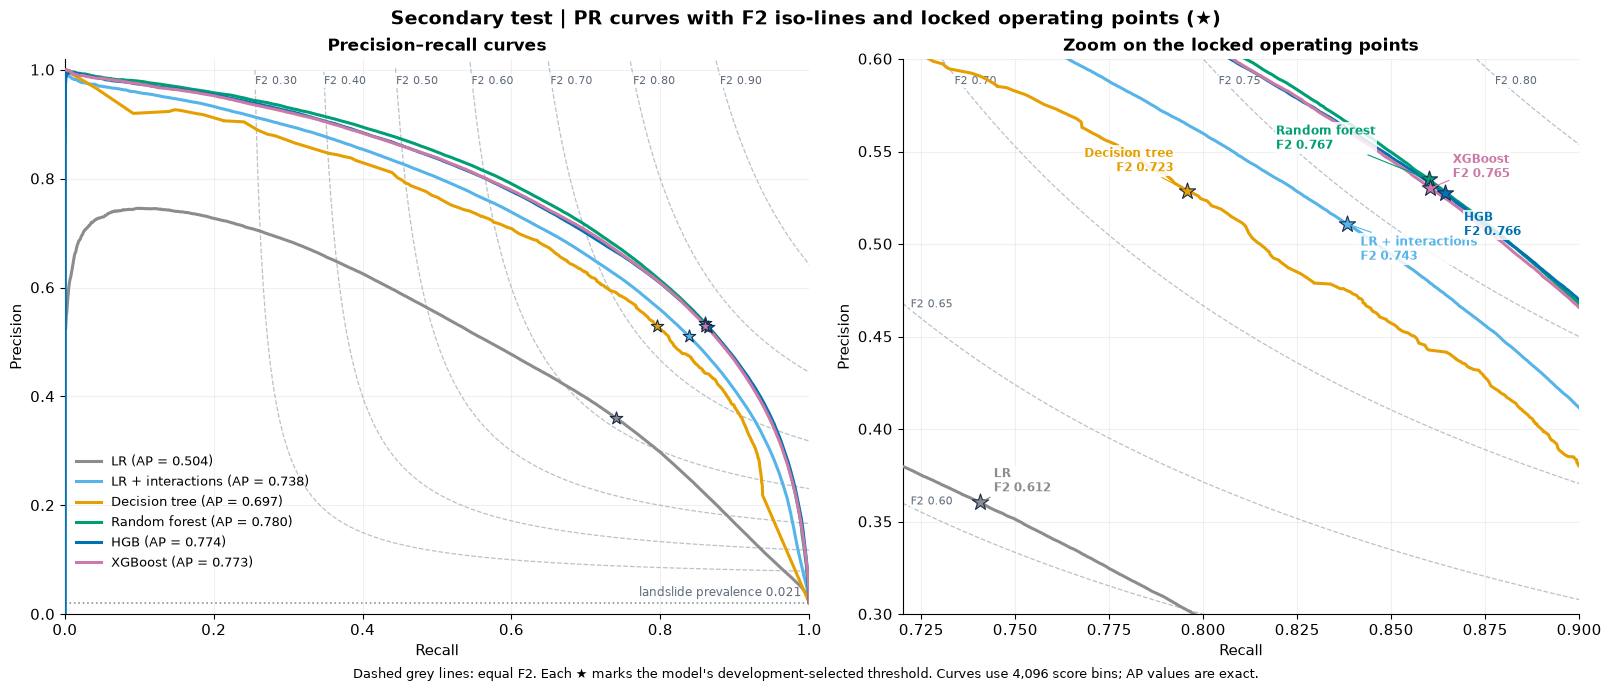

In [5]:
# Comparison — Step 4b: PR curves with F2 iso-lines (clean layout).
# Uses cmp_pr_curves, cmp_average_precision, operating and prevalence from Step 4.


def cmp_draw_f2_isolines(ax, levels, xlim, ylim):
    """Draw equal-F2 lines inside the axes and label each one inside the visible area."""
    x_margin = 0.012 * (xlim[1] - xlim[0])
    y_margin = 0.03 * (ylim[1] - ylim[0])
    recall_grid = np.linspace(xlim[0], xlim[1], 800)

    for level in levels:
        r = recall_grid[recall_grid > 0.8 * level + 1e-9]
        if len(r) == 0:
            continue
        p = level * r / (5 * r - 4 * level)
        inside = (p >= ylim[0]) & (p <= ylim[1])
        if not inside.any():
            continue
        ax.plot(r[inside], p[inside], color="#B8C2CC", linewidth=0.9,
                linestyle="--", zorder=1)

        # Label where the line leaves the top edge; otherwise at the left edge.
        p_top = ylim[1] - y_margin
        r_top = 4 * level * p_top / (5 * p_top - level)
        if xlim[0] + x_margin <= r_top <= xlim[1] - 6 * x_margin:
            x_text, y_text, va = r_top, p_top, "top"
        else:
            x_text = xlim[0] + x_margin
            denominator = 5 * x_text - 4 * level
            if denominator <= 0:
                continue
            y_text = level * x_text / denominator
            if not (ylim[0] + y_margin < y_text < ylim[1] - y_margin):
                continue
            va = "bottom"
        ax.text(x_text, y_text, f"F2 {level:.2f}", fontsize=8, color="#5F6B7A",
                ha="left", va=va, clip_on=True, zorder=2,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.6, "alpha": 0.85})


label_offsets = {
    "LR": (10, 8),
    "LR + interactions": (10, -26),
    "Decision tree": (-10, 14),
    "Random forest": (-110, 22),
    "HGB": (14, -30),
    "XGBoost": (16, 8),
}
label_alignment = {"Decision tree": "right", "Random forest": "left"}

with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.8), constrained_layout=True,
                             gridspec_kw={"width_ratios": [1.1, 1]})

    panels = (
        (axes[0], False, (0.0, 1.0), (0.0, 1.02), [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]),
        (axes[1], True, (0.72, 0.90), (0.30, 0.60), [0.60, 0.65, 0.70, 0.75, 0.80]),
    )

    for ax, zoom, xlim, ylim, levels in panels:
        cmp_draw_f2_isolines(ax, levels, xlim, ylim)

        for model in cmp_models:
            recall_curve, precision_curve = cmp_pr_curves[model]
            ax.plot(recall_curve, precision_curve, color=CMP_COLORS[model], linewidth=2.2,
                    label=f"{model} (AP = {cmp_average_precision[model]:.3f})", zorder=3)
            ax.scatter(operating.loc[model, "Recall"], operating.loc[model, "Precision"],
                       s=150 if zoom else 90, marker="*", color=CMP_COLORS[model],
                       edgecolor="#172B4D", linewidth=0.8, zorder=5)
            if zoom:
                ax.annotate(
                    f"{model}\nF2 {operating.loc[model, 'F2']:.3f}",
                    (operating.loc[model, "Recall"], operating.loc[model, "Precision"]),
                    xytext=label_offsets[model], textcoords="offset points",
                    ha=label_alignment.get(model, "left"), fontsize=8.5,
                    color=CMP_COLORS[model], fontweight="bold", zorder=6,
                    arrowprops={"arrowstyle": "-", "color": CMP_COLORS[model], "linewidth": 0.8},
                    bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.8, "alpha": 0.85},
                )

        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.grid(alpha=0.18)

        if zoom:
            ax.set_title("Zoom on the locked operating points", fontweight="bold")
        else:
            ax.axhline(prevalence, color="#8795A1", linestyle=":", linewidth=1.2)
            ax.text(0.99, prevalence + 0.012, f"landslide prevalence {prevalence:.3f}",
                    fontsize=8.5, color="#5F6B7A", ha="right")
            ax.set_title("Precision–recall curves", fontweight="bold")
            ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 0.06), fontsize=9)

    fig.suptitle("Secondary test | PR curves with F2 iso-lines and locked operating points (★)",
                 fontsize=14, fontweight="bold")
    fig.supxlabel("Dashed grey lines: equal F2. Each ★ marks the model's development-selected "
                  "threshold. Curves use 4,096 score bins; AP values are exact.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_pr_curves_f2_isolines.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

**Result — precision–recall curves with F2 iso-lines (secondary test).** The figure combines each classifier's full precision–recall trade-off with lines of equal F2 and marks the operating point given by its development-selected threshold (★).

- **Ranking quality.** The PR curves of random forest, HGB, and XGBoost almost coincide over the full recall range and have the highest average precision (0.780, 0.774, and 0.773). Interaction LR (AP 0.738) lies slightly lower, the decision tree (0.697) lower again, and raw-feature LR (0.504) far below. Raw-feature LR never exceeds a precision of about 0.75, even at very low recall, so even its most confident predictions contain many false alarms. The decision tree's curve shows steps and flat segments, reflecting the small number of distinct probability values produced by a single tree.

- **Operating points.** The three ensemble models operate at practically the same point (recall 0.860–0.864, precision 0.527–0.535) and lie on the same F2 line (0.765–0.767). Interaction LR (recall 0.838, precision 0.511; F2 0.743), the decision tree (0.796, 0.529; F2 0.723), and raw-feature LR (0.741, 0.360; F2 0.612) lie on clearly lower F2 lines. At the recall level of the ensembles (about 0.86), the interaction-LR curve reaches a precision of only about 0.47, which explains its lower F2.

- **Threshold choice.** Each locked operating point lies close to where its curve touches the highest reachable F2 line, confirming that thresholds selected on development data are near-optimal on the independent test images. Beyond these points, all curves drop steeply, so higher recall would require a disproportionate increase in false alarms.

Overall, the figure shows that the three ensemble models are equivalent in both ranking quality and operating performance, and that their advantage over the other classifiers is consistent across the whole precision–recall range rather than an effect of the chosen thresholds.

UNIFORM CALIBRATION METRICS (secondary test, 15 uniform bins)
                    Brier  ECE_15  MCE_15
Model                                    
LR                0.01404 0.00416 0.22827
LR + interactions 0.00976 0.00273 0.09188
Decision tree     0.03560 0.04261 0.74575
Random forest     0.00879 0.00102 0.01467
HGB               0.00902 0.00183 0.08653
XGBoost           0.00895 0.00112 0.05284

Loading final models...

Timing prediction on 100 test images (1,638,400 pixels), 2 threads, 3 repeats...
  LR                   0.085 s per million pixels | reproduces saved scores: True (max difference 0.0e+00)
  LR + interactions    0.685 s per million pixels | reproduces saved scores: True (max difference 0.0e+00)
  Decision tree        0.047 s per million pixels | reproduces saved scores: True (max difference 3.0e-08)
  Random forest        4.688 s per million pixels | reproduces saved scores: True (max difference 3.0e-08)
  HGB                  6.525 s per million pixels | reproduces save

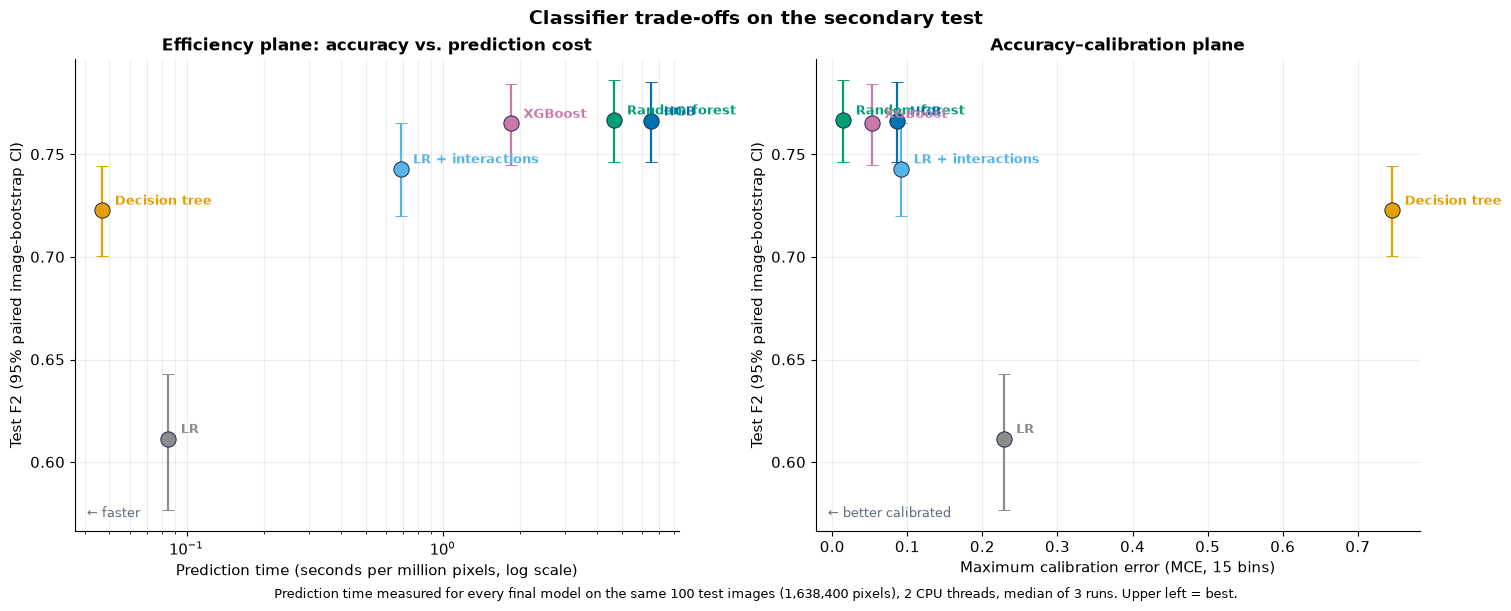


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\comparison


In [6]:
# Comparison — Step 5: final summary table, uniform calibration metrics, and efficiency plane.
# Uses the aligned test scores from Step 4 and the saved final models. No model is retrained.

import time
from threadpoolctl import threadpool_limits

# ------------------------------------------------------------
# 1. Uniform calibration metrics from the aligned test scores.
# ------------------------------------------------------------
CMP_CAL_BINS = 15
calibration_rows = []

for m, model in enumerate(cmp_models):
    count = np.zeros(CMP_CAL_BINS)
    score_sum = np.zeros(CMP_CAL_BINS)
    positive_sum = np.zeros(CMP_CAL_BINS)
    squared_error = 0.0

    for start in range(0, n_test, 64):
        scores = cmp_test_scores[m, start:start + 64].astype(np.float64).ravel()
        labels = cmp_test_labels[start:start + 64].ravel().astype(np.float64)
        bins = np.minimum((scores * CMP_CAL_BINS).astype(np.int32), CMP_CAL_BINS - 1)
        count += np.bincount(bins, minlength=CMP_CAL_BINS)
        score_sum += np.bincount(bins, weights=scores, minlength=CMP_CAL_BINS)
        positive_sum += np.bincount(bins, weights=labels, minlength=CMP_CAL_BINS)
        squared_error += float(np.sum((scores - labels) ** 2))

    nonempty = count > 0
    gap = np.abs(score_sum[nonempty] / count[nonempty] - positive_sum[nonempty] / count[nonempty])
    calibration_rows.append({
        "Model": model,
        "Brier": squared_error / count.sum(),
        "ECE_15": float(np.sum(count[nonempty] / count.sum() * gap)),
        "MCE_15": float(gap.max()),
    })

cmp_calibration = pd.DataFrame(calibration_rows).set_index("Model")
print("UNIFORM CALIBRATION METRICS (secondary test, 15 uniform bins)")
print(cmp_calibration.to_string(float_format=lambda x: f"{x:.5f}"))

# ------------------------------------------------------------
# 2. Load the final saved models.
# ------------------------------------------------------------
def cmp_unwrap(obj):
    if isinstance(obj, dict):
        for key in ("model", "estimator", "pipeline"):
            if key in obj:
                return obj[key]
    return obj


def cmp_fit_seconds(obj):
    if isinstance(obj, dict):
        for key in ("fit_seconds", "fit_time_seconds", "training_seconds"):
            if key in obj:
                return float(obj[key])
    return np.nan


print("\nLoading final models...", flush=True)
cmp_final_models = {}
cmp_final_fit_seconds = {}

lr_models = joblib.load(cmp_lr_folder / "project_state.joblib")["models"]
lr_base = lr_models["lr_final_base_model"]
lr_calibrator = lr_models.get("lr_final_calibrator")
lr_interaction = lr_models["lr_interaction_final_base_model"]

cmp_final_models["LR"] = [
    ("calibrator(decision_function)",
     lambda X: lr_calibrator.predict_proba(lr_base.decision_function(X).reshape(-1, 1))[:, 1]),
    ("calibrator(probability)",
     lambda X: lr_calibrator.predict_proba(lr_base.predict_proba(X)[:, 1].reshape(-1, 1))[:, 1]),
    ("base predict_proba", lambda X: lr_base.predict_proba(X)[:, 1]),
]
cmp_final_models["LR + interactions"] = [
    ("predict_proba", lambda X: lr_interaction.predict_proba(X)[:, 1]),
]

dt_bundle = cmp_get(joblib.load(cmp_dt_folder / "final_model_and_holdout.joblib"),
                    "dt_final_model_bundle", "Decision tree")
dt_model = cmp_unwrap(dt_bundle)
dt_positive = int(np.flatnonzero(dt_model.classes_ == 1)[0])
cmp_final_models["Decision tree"] = [
    ("predict_proba", lambda X: dt_model.predict_proba(X)[:, dt_positive])]
cmp_final_fit_seconds["Decision tree"] = cmp_fit_seconds(dt_bundle)

rf_object = joblib.load(cmp_rf_paths["final_model"])
rf_model = cmp_unwrap(rf_object)
if hasattr(rf_model, "n_jobs"):
    rf_model.set_params(n_jobs=2)
rf_positive = int(np.flatnonzero(rf_model.classes_ == 1)[0])
cmp_final_models["Random forest"] = [
    ("predict_proba", lambda X: rf_model.predict_proba(X)[:, rf_positive])]
cmp_final_fit_seconds["Random forest"] = cmp_fit_seconds(rf_object)

for model, folder, prefix in (("HGB", "hist_gradient_boosting", "hgb"),
                              ("XGBoost", "xgboost", "xgb")):
    bundle = joblib.load(CMP_ARTIFACTS / "classifier_comparison" / folder
                         / f"{prefix}_comparison_bundle.joblib")
    model_object = joblib.load(bundle["final_model_path"])
    estimator = cmp_unwrap(model_object)
    if model == "XGBoost":
        estimator.set_params(n_jobs=2)
    cmp_final_models[model] = [
        ("predict_proba", lambda X, e=estimator: e.predict_proba(X)[:, 1])]
    cmp_final_fit_seconds[model] = cmp_fit_seconds(model_object)

# ------------------------------------------------------------
# 3. Fair prediction timing on identical images (2 threads, median of 3 runs).
# ------------------------------------------------------------
CMP_TIMING_IMAGES = 100
CMP_TIMING_REPEATS = 3


def cmp_load_features(image_id):
    with h5py.File(cmp_image_dir / f"image_{image_id}.h5", "r") as handle:
        names = []
        handle.visititems(lambda name, obj: names.append(name)
                          if isinstance(obj, h5py.Dataset) and obj.shape == (128, 128, 14) else None)
        assert len(names) == 1
        return np.asarray(handle[names[0]][()], dtype=np.float32).reshape(-1, 14)


timing_ids = cmp_test_order[:CMP_TIMING_IMAGES]
X_timing = np.concatenate([cmp_load_features(i) for i in timing_ids])
timing_pixels = X_timing.shape[0]

timing_rows = []
print(f"\nTiming prediction on {CMP_TIMING_IMAGES} test images ({timing_pixels:,} pixels), "
      f"2 threads, {CMP_TIMING_REPEATS} repeats...", flush=True)

with threadpool_limits(limits=2):
    for m, model in enumerate(cmp_models):
        saved = cmp_test_scores[m, :CMP_TIMING_IMAGES].reshape(-1).astype(np.float64)

        # Choose the prediction route that reproduces the saved test scores.
        chosen_name, chosen_function, max_difference = None, None, np.inf
        for name, function in cmp_final_models[model]:
            try:
                predicted = np.asarray(function(X_timing[:CMP_PIXELS_PER_IMAGE]), dtype=np.float64)
                difference = float(np.max(np.abs(predicted - saved[:CMP_PIXELS_PER_IMAGE])))
            except Exception as error:
                print(f"  {model}: route '{name}' not usable ({type(error).__name__}).")
                continue
            if difference < max_difference:
                chosen_name, chosen_function, max_difference = name, function, difference
            if difference <= 1e-5:
                break

        if chosen_function is None:
            print(f"  {model}: no usable prediction route — timing skipped.")
            timing_rows.append({"Model": model, "Prediction_route": "not available",
                                "Reproduces_saved_scores": False,
                                "Seconds_per_million_pixels": np.nan})
            continue

        durations = []
        for _ in range(CMP_TIMING_REPEATS):
            started = time.perf_counter()
            predicted = chosen_function(X_timing)
            durations.append(time.perf_counter() - started)

        full_difference = float(np.max(np.abs(np.asarray(predicted, dtype=np.float64) - saved)))
        reproduces = full_difference <= 1e-5
        seconds_per_million = float(np.median(durations)) / timing_pixels * 1e6
        timing_rows.append({
            "Model": model,
            "Prediction_route": chosen_name,
            "Reproduces_saved_scores": reproduces,
            "Max_score_difference": full_difference,
            "Seconds_per_million_pixels": seconds_per_million,
            "Estimated_seconds_full_test": seconds_per_million * n_test * PIX / 1e6,
        })
        print(f"  {model:<18} {seconds_per_million:7.3f} s per million pixels | "
              f"reproduces saved scores: {reproduces} (max difference {full_difference:.1e})",
              flush=True)

cmp_timing = pd.DataFrame(timing_rows).set_index("Model")

# ------------------------------------------------------------
# 4. Final summary table.
# ------------------------------------------------------------
summary_rows = []
for m, model in enumerate(cmp_models):
    outer_low, outer_high = np.quantile(cmp_results["Outer"]["bootstrap_f2"][:, m], [0.025, 0.975])
    test_low, test_high = np.quantile(cmp_results["Test"]["bootstrap_f2"][:, m], [0.025, 0.975])
    test_row = cmp_pooled[(cmp_pooled["Stage"] == "Test") & (cmp_pooled["Model"] == model)].iloc[0]
    outer_row = cmp_pooled[(cmp_pooled["Stage"] == "Outer") & (cmp_pooled["Model"] == model)].iloc[0]
    summary_rows.append({
        "Model": model,
        "Threshold": CMP_THRESHOLDS[model],
        "Outer_F2": outer_row["F2"], "Outer_F2_CI_low": outer_low, "Outer_F2_CI_high": outer_high,
        "Test_F2": test_row["F2"], "Test_F2_CI_low": test_low, "Test_F2_CI_high": test_high,
        "Test_Precision": test_row["Precision"], "Test_Recall": test_row["Recall"],
        "Test_Specificity": test_row["Specificity"], "Test_IoU": test_row["IoU"],
        "Test_AP": cmp_average_precision[model],
        "Test_Brier": cmp_calibration.loc[model, "Brier"],
        "Test_ECE_15": cmp_calibration.loc[model, "ECE_15"],
        "Test_MCE_15": cmp_calibration.loc[model, "MCE_15"],
        "Prediction_s_per_Mpx": cmp_timing.loc[model, "Seconds_per_million_pixels"],
        "Final_fit_seconds": cmp_final_fit_seconds.get(model, np.nan),
    })

cmp_summary = pd.DataFrame(summary_rows)
cmp_summary.to_csv(CMP_DIR / "final_summary_table.csv", index=False)
cmp_timing.to_csv(CMP_DIR / "prediction_timing.csv")

report_table = pd.DataFrame({
    "Model": cmp_summary["Model"],
    "Thr.": cmp_summary["Threshold"].map("{:.2f}".format),
    "Outer F2 [95% CI]": [f"{f:.4f} [{l:.4f}, {h:.4f}]" for f, l, h in
                          zip(cmp_summary["Outer_F2"], cmp_summary["Outer_F2_CI_low"],
                              cmp_summary["Outer_F2_CI_high"])],
    "Test F2 [95% CI]": [f"{f:.4f} [{l:.4f}, {h:.4f}]" for f, l, h in
                         zip(cmp_summary["Test_F2"], cmp_summary["Test_F2_CI_low"],
                             cmp_summary["Test_F2_CI_high"])],
    "Prec.": cmp_summary["Test_Precision"].map("{:.3f}".format),
    "Rec.": cmp_summary["Test_Recall"].map("{:.3f}".format),
    "IoU": cmp_summary["Test_IoU"].map("{:.3f}".format),
    "AP": cmp_summary["Test_AP"].map("{:.3f}".format),
    "Brier": cmp_summary["Test_Brier"].map("{:.4f}".format),
    "MCE": cmp_summary["Test_MCE_15"].map("{:.3f}".format),
    "s / Mpx": cmp_summary["Prediction_s_per_Mpx"].map("{:.3f}".format),
})
report_table.to_csv(CMP_DIR / "final_summary_table_report.csv", index=False)

print("\nFINAL SUMMARY TABLE (test metrics on 760 secondary-test images)")
print(report_table.to_string(index=False))

# ------------------------------------------------------------
# 5. Figure: efficiency plane and accuracy–calibration plane.
# ------------------------------------------------------------
with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

    for ax, x_column, x_label, title, log_x in (
        (axes[0], "Prediction_s_per_Mpx", "Prediction time (seconds per million pixels, log scale)",
         "Efficiency plane: accuracy vs. prediction cost", True),
        (axes[1], "Test_MCE_15", "Maximum calibration error (MCE, 15 bins)",
         "Accuracy–calibration plane", False),
    ):
        for _, row in cmp_summary.iterrows():
            if not np.isfinite(row[x_column]):
                continue
            colour = CMP_COLORS[row["Model"]]
            ax.errorbar(row[x_column], row["Test_F2"],
                        yerr=[[row["Test_F2"] - row["Test_F2_CI_low"]],
                              [row["Test_F2_CI_high"] - row["Test_F2"]]],
                        fmt="o", color=colour, markersize=11, capsize=4, elinewidth=1.6,
                        markeredgecolor="#172B4D", markeredgewidth=0.7)
            ax.annotate(row["Model"], (row[x_column], row["Test_F2"]), xytext=(9, 4),
                        textcoords="offset points", fontsize=9.5, color=colour, fontweight="bold")
        if log_x:
            ax.set_xscale("log")
        ax.set_xlabel(x_label)
        ax.set_ylabel("Test F2 (95% paired image-bootstrap CI)")
        ax.set_title(title, fontweight="bold")
        ax.grid(alpha=0.22, which="both")

    axes[0].text(0.02, 0.03, "← faster", transform=axes[0].transAxes, fontsize=9, color="#5F6B7A")
    axes[1].text(0.02, 0.03, "← better calibrated", transform=axes[1].transAxes,
                 fontsize=9, color="#5F6B7A")

    fig.suptitle("Classifier trade-offs on the secondary test", fontsize=14, fontweight="bold")
    fig.supxlabel(f"Prediction time measured for every final model on the same {CMP_TIMING_IMAGES} "
                  f"test images ({timing_pixels:,} pixels), 2 CPU threads, median of "
                  f"{CMP_TIMING_REPEATS} runs. Upper left = best.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_efficiency_calibration_planes.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", CMP_DIR)

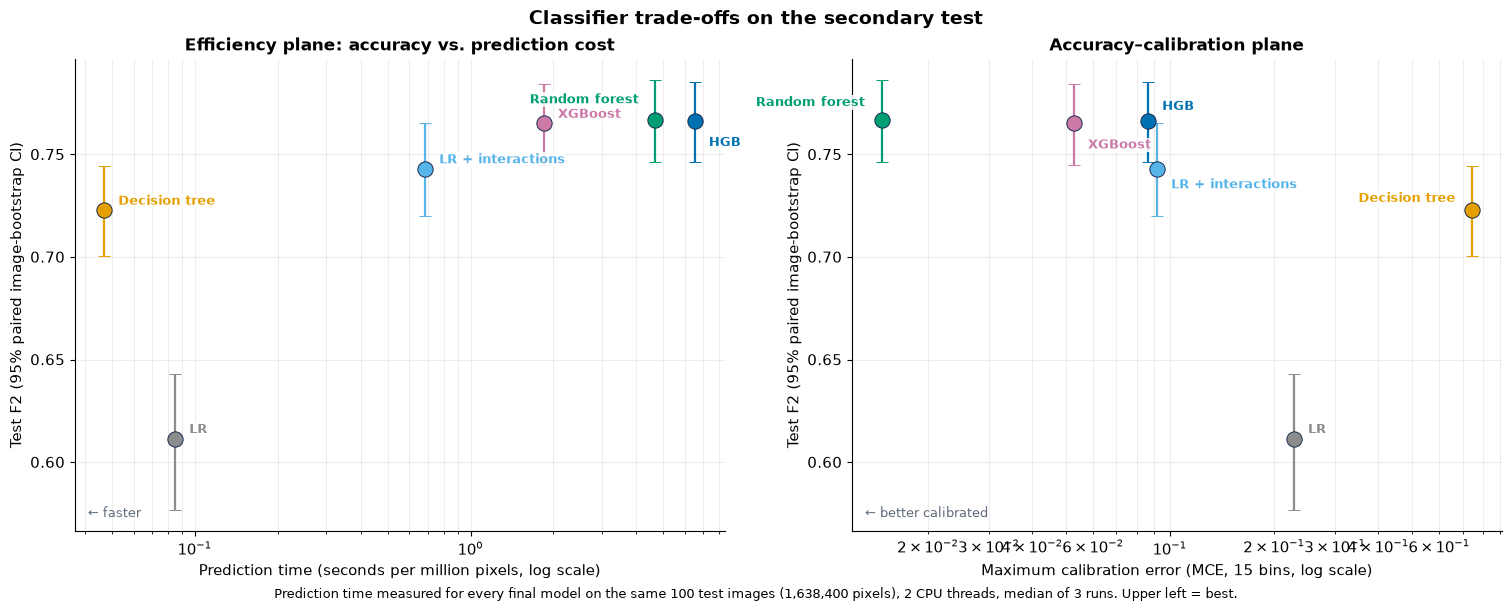

In [7]:
# Comparison — Step 5b: efficiency and accuracy–calibration planes (clean layout).
# Uses cmp_summary from Step 5.

label_offsets = {
    "Efficiency": {
        "LR": (10, 4, "left"), "LR + interactions": (10, 4, "left"),
        "Decision tree": (10, 4, "left"), "XGBoost": (10, 4, "left"),
        "Random forest": (-12, 12, "right"), "HGB": (10, -18, "left"),
    },
    "Calibration": {
        "LR": (10, 4, "left"), "LR + interactions": (10, -14, "left"),
        "Decision tree": (-12, 6, "right"), "XGBoost": (10, -18, "left"),
        "Random forest": (-12, 10, "right"), "HGB": (10, 8, "left"),
    },
}

with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

    for ax, key, x_column, x_label, title in (
        (axes[0], "Efficiency", "Prediction_s_per_Mpx",
         "Prediction time (seconds per million pixels, log scale)",
         "Efficiency plane: accuracy vs. prediction cost"),
        (axes[1], "Calibration", "Test_MCE_15",
         "Maximum calibration error (MCE, 15 bins, log scale)",
         "Accuracy–calibration plane"),
    ):
        for _, row in cmp_summary.iterrows():
            colour = CMP_COLORS[row["Model"]]
            ax.errorbar(row[x_column], row["Test_F2"],
                        yerr=[[row["Test_F2"] - row["Test_F2_CI_low"]],
                              [row["Test_F2_CI_high"] - row["Test_F2"]]],
                        fmt="o", color=colour, markersize=11, capsize=4, elinewidth=1.6,
                        markeredgecolor="#172B4D", markeredgewidth=0.7, zorder=3)
            dx, dy, ha = label_offsets[key][row["Model"]]
            ax.annotate(row["Model"], (row[x_column], row["Test_F2"]), xytext=(dx, dy),
                        textcoords="offset points", ha=ha, fontsize=9.5, color=colour,
                        fontweight="bold", zorder=4,
                        bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.6, "alpha": 0.85})
        ax.set_xscale("log")
        ax.set_xlabel(x_label)
        ax.set_ylabel("Test F2 (95% paired image-bootstrap CI)")
        ax.set_title(title, fontweight="bold")
        ax.grid(alpha=0.22, which="both")

    axes[0].text(0.02, 0.03, "← faster", transform=axes[0].transAxes, fontsize=9, color="#5F6B7A")
    axes[1].text(0.02, 0.03, "← better calibrated", transform=axes[1].transAxes,
                 fontsize=9, color="#5F6B7A")

    fig.suptitle("Classifier trade-offs on the secondary test", fontsize=14, fontweight="bold")
    fig.supxlabel(f"Prediction time measured for every final model on the same {CMP_TIMING_IMAGES} "
                  f"test images ({timing_pixels:,} pixels), 2 CPU threads, median of "
                  f"{CMP_TIMING_REPEATS} runs. Upper left = best.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_efficiency_calibration_planes.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

**Result — final summary, calibration, and efficiency.**

| Model | Thr. | Outer F2 [95% CI] | Test F2 [95% CI] | Precision | Recall | IoU | AP | Brier | MCE | s / Mpx |
|---|---|---|---|---|---|---|---|---|---|---|
| LR | 0.10 | 0.6291 [0.6142, 0.6429] | 0.6116 [0.5768, 0.6431] | 0.360 | 0.741 | 0.320 | 0.504 | 0.0140 | 0.228 | 0.085 |
| LR + interactions | 0.11 | 0.7478 [0.7376, 0.7572] | 0.7430 [0.7198, 0.7653] | 0.511 | 0.838 | 0.465 | 0.738 | 0.0098 | 0.092 | 0.685 |
| Decision tree | 0.92 | 0.7376 [0.7279, 0.7467] | 0.7228 [0.7004, 0.7444] | 0.529 | 0.796 | 0.466 | 0.697 | 0.0356 | 0.746 | 0.047 |
| Random forest | 0.17 | **0.7761** [0.7675, 0.7844] | **0.7668** [0.7465, 0.7862] | **0.535** | 0.860 | **0.492** | **0.780** | **0.0088** | **0.015** | 4.688 |
| HGB | 0.13 | 0.7739 [0.7652, 0.7821] | 0.7663 [0.7465, 0.7854] | 0.527 | **0.864** | 0.487 | 0.774 | 0.0090 | 0.087 | 6.525 |
| XGBoost | 0.14 | 0.7730 [0.7642, 0.7812] | 0.7651 [0.7449, 0.7844] | 0.530 | 0.860 | 0.488 | 0.773 | 0.0090 | 0.053 | 1.849 |

*Test metrics on the 760 secondary-test images; CIs from 5,000 paired whole-image bootstrap resamples. Calibration uses 15 uniform bins for all models. Prediction time is in seconds per million pixels, measured for every final model on the same 100 test images (2 CPU threads, median of 3 runs); every model reproduced its saved test scores exactly.*

*Calibration.* Calibration differs much more between classifiers than F2 does. Random forest produces the best-calibrated probabilities (MCE 0.015, Brier 0.0088), followed by XGBoost (MCE 0.053) and HGB (0.087), which perform equally well in F2. The decision tree is strongly miscalibrated (MCE 0.746, Brier 0.036): its few distinct leaf probabilities overestimate the landslide probability, which is also why its F2-optimal threshold is as high as 0.92. Raw-feature LR is also poorly calibrated (MCE 0.228), whereas interaction LR improves this considerably (0.092). Only random forest, XGBoost, and HGB therefore provide probabilities that could be used directly, for example for risk maps.

*Efficiency.* Prediction cost spans more than two orders of magnitude. The decision tree (0.05 s per million pixels) and raw-feature LR (0.09 s) are fastest but clearly less accurate. Among the three equally accurate ensemble models, XGBoost predicts 2.5 times faster than random forest and 3.5 times faster than HGB (1.8 vs. 4.7 vs. 6.5 s per million pixels). Interaction LR offers an attractive middle ground: about 97% of the ensembles' F2 at roughly a third of XGBoost's prediction time. Training effort, which is not shown in the figure, differs even more: the random forest search required about 40 hours, compared with roughly 1–2 hours each for the HGB and XGBoost searches.

*Overall.* Random forest, HGB, and XGBoost are statistically equivalent in detection performance. Random forest offers the best-calibrated probabilities, while XGBoost combines good calibration with the fastest prediction and much lower training cost, which makes it the most practical choice for large-area mapping. When interpretability or very low computational cost matters most, interaction LR is a strong, transparent alternative.

BAYESIAN BOOTSTRAP — F2 difference (A − B), ROPE = ±0.01, 5,000 posterior draws

OUTER
                            A − B Mean diff            95% CrI P(A better) P(equivalent)               Decision
               LR − Random forest   -0.1470 [-0.1566, -0.1379]       0.000         0.000  Practically different
LR + interactions − Random forest   -0.0283 [-0.0327, -0.0245]       0.000         0.000  Practically different
    Decision tree − Random forest   -0.0386 [-0.0407, -0.0365]       0.000         0.000  Practically different
              HGB − Random forest   -0.0023 [-0.0037, -0.0010]       0.001         1.000 Practically equivalent
          XGBoost − Random forest   -0.0032 [-0.0046, -0.0019]       0.000         1.000 Practically equivalent
                    HGB − XGBoost   +0.0009 [-0.0004, +0.0022]       0.918         1.000 Practically equivalent

TEST
                            A − B Mean diff            95% CrI P(A better) P(equivalent)               Decision
           

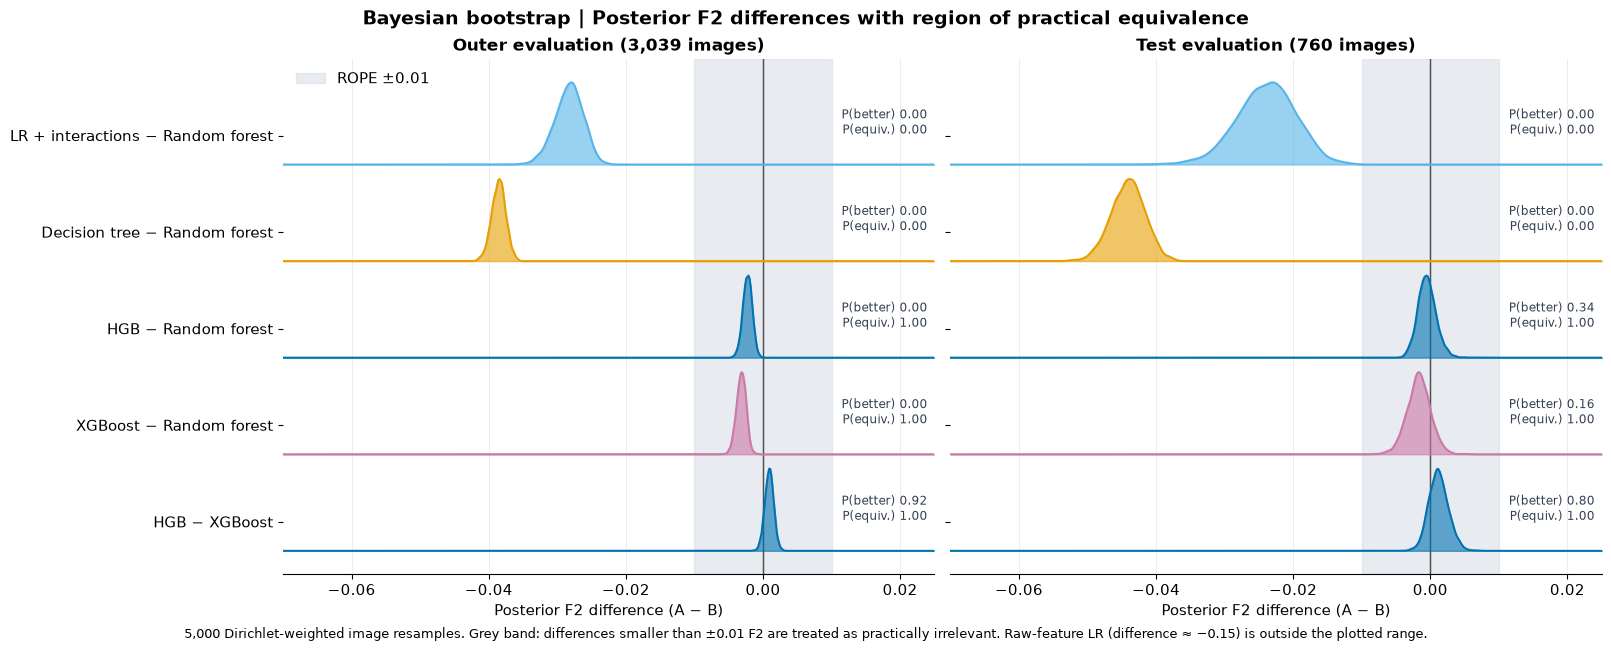

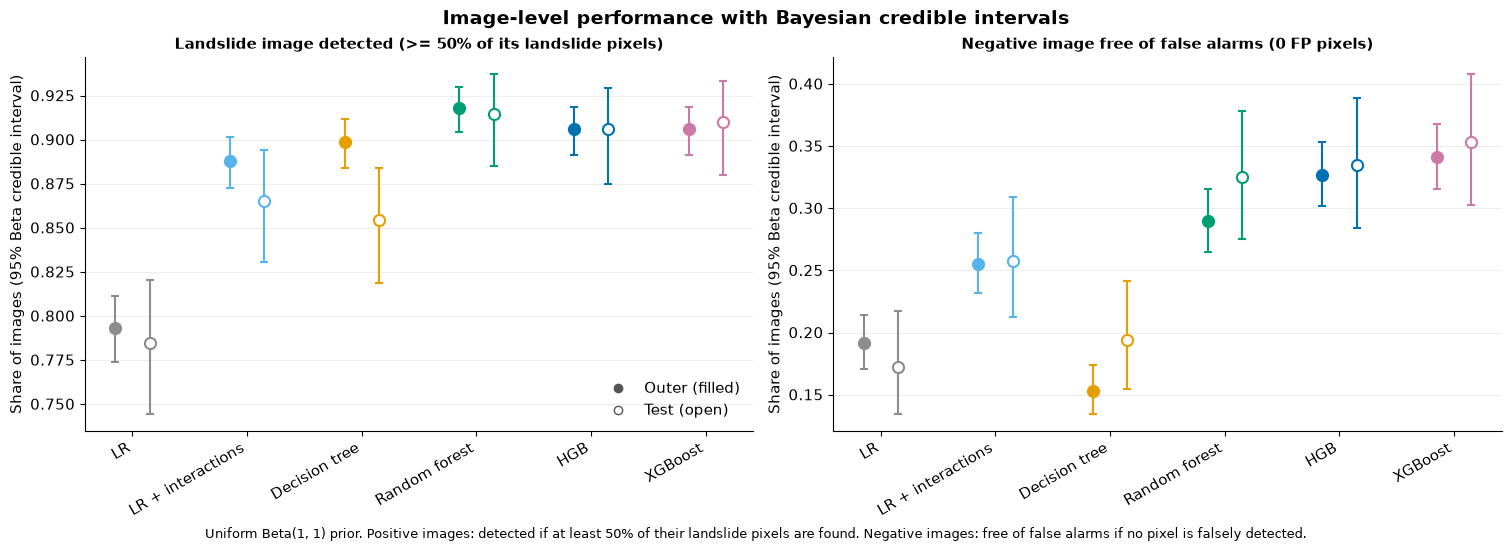


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\comparison


In [8]:
# Comparison — Step 6: Bayesian comparison (Bayesian bootstrap + ROPE)
# and image-level hypothesis tests (Cochran's Q, exact McNemar, Beta posteriors).
# Unit of analysis: image. Uses the Step 1 per-image counts only.

from scipy.stats import gaussian_kde, chi2, binomtest
from scipy.stats import beta as beta_distribution

CMP_ROPE = 0.01                 # region of practical equivalence for F2, fixed in advance
CMP_POSTERIOR_DRAWS = 5000
CMP_BETA_DRAWS = 200_000
CMP_DETECTION_RECALL = 0.5      # a landslide image counts as detected if >= 50% of its pixels are found


def cmp_bayesian_bootstrap_f2(counts, draws=CMP_POSTERIOR_DRAWS, seed=CMP_RANDOM_STATE):
    """Bayesian bootstrap: Dirichlet(1, ..., 1) weights over images, identical for all models."""
    n_images = counts.shape[1]
    flat = counts.transpose(1, 0, 2).reshape(n_images, -1).astype(np.float64)
    rng = np.random.default_rng(seed)
    posterior = np.empty((draws, counts.shape[0]))
    for start in range(0, draws, 250):
        stop = min(start + 250, draws)
        weights = rng.dirichlet(np.ones(n_images), size=stop - start)
        sums = (weights @ flat).reshape(stop - start, counts.shape[0], 4)
        posterior[start:stop] = cmp_f2_from_sums(*np.moveaxis(sums, -1, 0))
    return posterior


def cmp_rope_decision(low, high, rope=CMP_ROPE):
    if low > -rope and high < rope:
        return "Practically equivalent"
    if high < -rope or low > rope:
        return "Practically different"
    return "Undecided"


# ------------------------------------------------------------
# 1. Bayesian bootstrap with ROPE.
# ------------------------------------------------------------
comparison_pairs = [(model, reference_model) for model in cmp_models if model != reference_model]
comparison_pairs.append(("HGB", "XGBoost"))

bayes_rows = []
cmp_posteriors = {}

for stage in ("Outer", "Test"):
    _, counts = cmp_stage_counts(stage)
    posterior = cmp_bayesian_bootstrap_f2(counts)
    cmp_posteriors[stage] = posterior

    for model_a, model_b in comparison_pairs:
        difference = (posterior[:, cmp_models.index(model_a)]
                      - posterior[:, cmp_models.index(model_b)])
        low, high = np.quantile(difference, [0.025, 0.975])
        bayes_rows.append({
            "Stage": stage, "Model_A": model_a, "Model_B": model_b,
            "Posterior_mean_difference": float(difference.mean()),
            "CrI95_low": float(low), "CrI95_high": float(high),
            "P_A_better": float((difference > 0).mean()),
            "P_practically_equivalent": float((np.abs(difference) < CMP_ROPE).mean()),
            "P_A_practically_worse": float((difference < -CMP_ROPE).mean()),
            "P_A_practically_better": float((difference > CMP_ROPE).mean()),
            "Decision": cmp_rope_decision(low, high),
        })

cmp_bayes = pd.DataFrame(bayes_rows)
cmp_bayes.to_csv(CMP_DIR / "bayesian_bootstrap_rope.csv", index=False)

print(f"BAYESIAN BOOTSTRAP — F2 difference (A − B), ROPE = ±{CMP_ROPE}, "
      f"{CMP_POSTERIOR_DRAWS:,} posterior draws")
for stage in ("Outer", "Test"):
    table = cmp_bayes[cmp_bayes["Stage"] == stage]
    print(f"\n{stage.upper()}")
    print(pd.DataFrame({
        "A − B": table["Model_A"] + " − " + table["Model_B"],
        "Mean diff": table["Posterior_mean_difference"].map("{:+.4f}".format),
        "95% CrI": [f"[{l:+.4f}, {h:+.4f}]" for l, h in zip(table["CrI95_low"], table["CrI95_high"])],
        "P(A better)": table["P_A_better"].map("{:.3f}".format),
        "P(equivalent)": table["P_practically_equivalent"].map("{:.3f}".format),
        "Decision": table["Decision"],
    }).to_string(index=False))

# ------------------------------------------------------------
# 2. Image-level binary outcomes: Cochran's Q, exact McNemar, Beta posteriors.
# ------------------------------------------------------------
def cmp_cochran_q(binary):
    """Cochran's Q for k related binary samples; binary has shape (models, images)."""
    data = binary.T.astype(float)
    k = data.shape[1]
    column_sums = data.sum(axis=0)
    row_sums = data.sum(axis=1)
    total = data.sum()
    denominator = k * total - np.sum(row_sums ** 2)
    q = (k - 1) * (k * np.sum(column_sums ** 2) - total ** 2) / denominator if denominator > 0 else 0.0
    return float(q), float(chi2.sf(q, k - 1))


image_rows = []
cochran_rows = []
n_vs_reference = n_models - 1
rng_beta = np.random.default_rng(CMP_RANDOM_STATE)

for stage in ("Outer", "Test"):
    _, counts = cmp_stage_counts(stage)
    tp, fn, fp = counts[:, :, 3], counts[:, :, 2], counts[:, :, 1]
    reference_pixels = tp[0] + fn[0]
    positive = reference_pixels > 0

    outcomes = {
        "Landslide image detected (>= 50% of its landslide pixels)":
            (tp[:, positive] / reference_pixels[positive]) >= CMP_DETECTION_RECALL,
        "Negative image free of false alarms (0 FP pixels)":
            fp[:, ~positive] == 0,
    }

    for outcome, binary in outcomes.items():
        q, q_p = cmp_cochran_q(binary)
        cochran_rows.append({"Stage": stage, "Outcome": outcome, "Images": binary.shape[1],
                             "Cochran_Q": q, "p_value": q_p})

        n_items = binary.shape[1]
        successes = binary.sum(axis=1)
        reference_draws = rng_beta.beta(1 + successes[reference_index],
                                        1 + n_items - successes[reference_index], CMP_BETA_DRAWS)

        for m, model in enumerate(cmp_models):
            low, high = beta_distribution.ppf([0.025, 0.975], 1 + successes[m],
                                              1 + n_items - successes[m])
            row = {
                "Stage": stage, "Outcome": outcome, "Model": model, "Images": n_items,
                "Successes": int(successes[m]), "Rate": successes[m] / n_items,
                "Beta_CrI_low": float(low), "Beta_CrI_high": float(high),
            }
            if m != reference_index:
                only_model = int(np.sum(binary[m] & ~binary[reference_index]))
                only_reference = int(np.sum(~binary[m] & binary[reference_index]))
                discordant = only_model + only_reference
                mcnemar_p = (binomtest(only_model, discordant, 0.5).pvalue
                             if discordant > 0 else 1.0)
                model_draws = rng_beta.beta(1 + successes[m], 1 + n_items - successes[m],
                                            CMP_BETA_DRAWS)
                row.update({
                    "Only_model": only_model, "Only_reference": only_reference,
                    "McNemar_exact_p": float(mcnemar_p),
                    "McNemar_p_Bonferroni": float(min(1.0, mcnemar_p * n_vs_reference)),
                    "P_rate_above_reference": float((model_draws > reference_draws).mean()),
                })
            image_rows.append(row)

cmp_image_tests = pd.DataFrame(image_rows)
cmp_cochran = pd.DataFrame(cochran_rows)
cmp_image_tests.to_csv(CMP_DIR / "image_level_tests.csv", index=False)
cmp_cochran.to_csv(CMP_DIR / "image_level_cochran_q.csv", index=False)

print("\n\nIMAGE-LEVEL OUTCOMES — COCHRAN'S Q (all six models, df = 5)")
print(cmp_cochran.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

for stage in ("Outer", "Test"):
    for outcome in cmp_image_tests["Outcome"].unique():
        table = cmp_image_tests[(cmp_image_tests["Stage"] == stage)
                                & (cmp_image_tests["Outcome"] == outcome)]
        print(f"\n{stage.upper()} — {outcome} (n = {int(table['Images'].iloc[0])} images; "
              f"reference: {reference_model})")
        print(pd.DataFrame({
            "Model": table["Model"],
            "Rate": table["Rate"].map("{:.3f}".format),
            "95% CrI": [f"[{l:.3f}, {h:.3f}]" for l, h in
                        zip(table["Beta_CrI_low"], table["Beta_CrI_high"])],
            "Only model / only ref.": [
                "—" if pd.isna(a) else f"{int(a)} / {int(b)}"
                for a, b in zip(table.get("Only_model"), table.get("Only_reference"))],
            "McNemar p (Bonf.)": table["McNemar_p_Bonferroni"].map(
                lambda p: "—" if pd.isna(p) else f"{p:.2e}"),
            "P(rate > ref.)": table["P_rate_above_reference"].map(
                lambda p: "—" if pd.isna(p) else f"{p:.3f}"),
        }).to_string(index=False))

print(f"\nMcNemar uses only discordant images (one model right, the other wrong); exact binomial "
      f"test, Bonferroni for {n_vs_reference} comparisons. Beta posteriors use a uniform Beta(1, 1) prior "
      "and treat the two rates as independent, which is conservative for paired data.")

# ------------------------------------------------------------
# Figure 1: posterior ridgeline of F2 differences with the ROPE.
# ------------------------------------------------------------
ridge_pairs = [(a, b) for a, b in comparison_pairs if a != "LR"]
x_grid = np.linspace(-0.07, 0.025, 600)

with plt.rc_context({"font.size": 10.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.4), sharey=True, constrained_layout=True)

    for ax, stage in zip(axes, ("Outer", "Test")):
        posterior = cmp_posteriors[stage]
        ax.axvspan(-CMP_ROPE, CMP_ROPE, color="#D9DEE7", alpha=0.6, zorder=0,
                   label=f"ROPE ±{CMP_ROPE}")
        ax.axvline(0, color="#333333", linewidth=1, zorder=1)

        for level, (model_a, model_b) in enumerate(ridge_pairs[::-1]):
            difference = (posterior[:, cmp_models.index(model_a)]
                          - posterior[:, cmp_models.index(model_b)])
            density = gaussian_kde(difference)(x_grid)
            density = 0.85 * density / density.max()
            colour = CMP_COLORS[model_a]
            ax.fill_between(x_grid, level, level + density, color=colour, alpha=0.6, zorder=2)
            ax.plot(x_grid, level + density, color=colour, linewidth=1.4, zorder=3)
            row = cmp_bayes[(cmp_bayes["Stage"] == stage) & (cmp_bayes["Model_A"] == model_a)
                            & (cmp_bayes["Model_B"] == model_b)].iloc[0]
            ax.text(0.024, level + 0.32,
                    f"P(better) {row['P_A_better']:.2f}\nP(equiv.) {row['P_practically_equivalent']:.2f}",
                    ha="right", fontsize=8.5, color="#344054")

        ax.set_yticks(np.arange(len(ridge_pairs)) + 0.3,
                      [f"{a} − {b}" for a, b in ridge_pairs[::-1]])
        ax.set_xlim(x_grid[0], x_grid[-1])
        ax.set_xlabel("Posterior F2 difference (A − B)")
        n_images = len(cmp_results[stage]["image_ids"])
        ax.set_title(f"{stage} evaluation ({n_images:,} images)", fontweight="bold")
        ax.grid(axis="x", alpha=0.22)
    axes[0].legend(frameon=False, loc="upper left")

    fig.suptitle("Bayesian bootstrap | Posterior F2 differences with region of practical equivalence",
                 fontsize=14, fontweight="bold")
    fig.supxlabel(f"{CMP_POSTERIOR_DRAWS:,} Dirichlet-weighted image resamples. Grey band: differences "
                  f"smaller than ±{CMP_ROPE} F2 are treated as practically irrelevant. Raw-feature LR "
                  "(difference ≈ −0.15) is outside the plotted range.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_bayesian_ridgeline.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# Figure 2: image-level rates with Beta credible intervals.
# ------------------------------------------------------------
with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    outcomes = list(cmp_image_tests["Outcome"].unique())
    fig, axes = plt.subplots(1, len(outcomes), figsize=(15, 5.4), constrained_layout=True)

    for ax, outcome in zip(axes, outcomes):
        x = np.arange(n_models)
        for shift, stage, fill in ((-0.15, "Outer", True), (0.15, "Test", False)):
            table = (cmp_image_tests[(cmp_image_tests["Stage"] == stage)
                                     & (cmp_image_tests["Outcome"] == outcome)]
                     .set_index("Model").loc[cmp_models])
            for position, model in zip(x, cmp_models):
                colour = CMP_COLORS[model]
                ax.errorbar(position + shift, table.loc[model, "Rate"],
                            yerr=[[table.loc[model, "Rate"] - table.loc[model, "Beta_CrI_low"]],
                                  [table.loc[model, "Beta_CrI_high"] - table.loc[model, "Rate"]]],
                            fmt="o", color=colour, markersize=8, capsize=3,
                            markerfacecolor=colour if fill else "white", markeredgewidth=1.5)
        ax.set_xticks(x, cmp_models, rotation=30, ha="right")
        ax.set_ylabel("Share of images (95% Beta credible interval)")
        ax.set_title(outcome, fontweight="bold", fontsize=11)
        ax.grid(axis="y", alpha=0.22)
    axes[0].plot([], [], "o", color="#555555", label="Outer (filled)")
    axes[0].plot([], [], "o", color="#555555", markerfacecolor="white", label="Test (open)")
    axes[0].legend(frameon=False, loc="lower right")

    fig.suptitle("Image-level performance with Bayesian credible intervals",
                 fontsize=14, fontweight="bold")
    fig.supxlabel("Uniform Beta(1, 1) prior. Positive images: detected if at least 50% of their landslide "
                  "pixels are found. Negative images: free of false alarms if no pixel is falsely detected.",
                  fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(CMP_DIR / f"cmp_image_level_bayesian.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", CMP_DIR)

**Result — Bayesian comparison and image-level tests.**

*Practical equivalence (Bayesian bootstrap, ROPE ±0.01 F2).* The posterior probability that HGB and XGBoost are practically equivalent to random forest is 1.00 in both the outer and the test evaluation, and the same holds for HGB versus XGBoost. All 95% credible intervals lie well inside the region of practical equivalence (largest absolute bound 0.0051). This turns the earlier frequentist result into a positive statement: on the outer evaluation, random forest is statistically better than HGB and XGBoost, but the posterior shows with near certainty that the difference is smaller than any practically relevant amount. Interaction LR (−0.024 to −0.028), the decision tree (−0.039 to −0.044), and raw-feature LR (≈ −0.15) are practically different from random forest with probability 1.00. The posterior probability that HGB is better than random forest is 0.34 on the test set (0.16 for XGBoost), so neither direction is favoured there.

*Image-level outcomes.* Cochran's Q shows that the six classifiers differ in both image-level outcomes (all p < 10⁻²⁵), mainly because of the weaker models.
- **Detection of landslide images** (≥ 50% of the landslide pixels found): random forest detects the most images (91.8% outer, 91.5% test), followed by HGB and XGBoost (90.6% outer, 90.6–91.0% test). Its advantage over the two boosting models is significant on the larger outer evaluation (exact McNemar, Bonferroni-adjusted p ≈ 0.01) but not on the test set (p = 1.0). Interaction LR (86–89%), the decision tree (85–90%), and raw-feature LR (79%) detect significantly fewer landslide images.
- **Negative images free of false alarms**: here the order reverses among the ensembles. XGBoost (34.1% outer, 35.4% test) and HGB (32.7%, 33.4%) leave more landslide-free images completely clean than random forest (28.9%, 32.5%), significantly on the outer evaluation (p < 10⁻⁵) but not on the test set. The decision tree (15–19%) and raw-feature LR (17–19%) raise false alarms in more than 80% of negative images.

*Interpretation.* The three ensemble models are practically equivalent in overall F2 but show a small, consistent difference in operating behaviour: random forest is slightly more sensitive (it finds a few more landslide images), whereas HGB and XGBoost are slightly more conservative (they keep more landslide-free images clean). This trade-off is significant only on the larger outer evaluation and is small in size, but it can guide model choice: random forest when missing a landslide is costlier, XGBoost or HGB when false alarms in stable terrain must be minimised.

In [9]:
# Comparison — Step 7: secondary tests for the remaining claims.
# (1) Size-dependence of the random-forest advantage (difference-in-differences),
# (2) Transfer from outer to test evaluation, (3) Secondary metrics vs. the reference model.
# Unit of analysis: image. Uses Step 1 counts, Step 2 bootstrap draws, and Step 4 test scores.

CMP_SECONDARY_BOOTSTRAP = 5000
reference_name = reference_model          # random forest (chosen in Step 2 from outer F2)
other_indices = [k for k in range(n_models) if k != reference_index]


def cmp_weight_chunks(n_items, repetitions=CMP_SECONDARY_BOOTSTRAP,
                      seed=CMP_RANDOM_STATE, chunk=250):
    """Identical multinomial image weights for every quantity computed from them."""
    rng = np.random.default_rng(seed)
    for start in range(0, repetitions, chunk):
        stop = min(start + chunk, repetitions)
        weights = rng.multinomial(n_items, np.full(n_items, 1 / n_items),
                                  size=stop - start).astype(np.float64)
        yield start, stop, weights


def cmp_two_sided_p(draws):
    return float(min(1.0, 2 * min((draws <= 0).mean(), (draws >= 0).mean())))


def cmp_holm(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    m = len(p_values)
    adjusted = np.empty(m)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p_values[index]))
        adjusted[index] = running
    return adjusted


def cmp_format_p(p):
    return f"< {1 / CMP_SECONDARY_BOOTSTRAP:.4f}" if p == 0 else f"{p:.4f}"


# ------------------------------------------------------------
# 1. Difference-in-differences: is the RF advantage larger for small landslides?
# ------------------------------------------------------------
did_rows = []
for stage in ("Outer", "Test"):
    _, counts = cmp_stage_counts(stage)
    reference_pixels = counts[0, :, 3] + counts[0, :, 2]
    positive = reference_pixels > 0
    coverage = 100 * reference_pixels[positive] / PIX
    positive_counts = counts[:, positive, :].astype(np.float64)
    small, large = coverage <= 1, coverage > 5
    n_items = positive_counts.shape[1]

    flat_small = (positive_counts * small[None, :, None]).transpose(1, 0, 2).reshape(n_items, -1)
    flat_large = (positive_counts * large[None, :, None]).transpose(1, 0, 2).reshape(n_items, -1)

    observed_small = cmp_f2_from_sums(*positive_counts[:, small].sum(axis=1).T)
    observed_large = cmp_f2_from_sums(*positive_counts[:, large].sum(axis=1).T)

    did_draws = np.empty((CMP_SECONDARY_BOOTSTRAP, n_models))
    for start, stop, weights in cmp_weight_chunks(n_items):
        f2_small = cmp_f2_from_sums(*np.moveaxis((weights @ flat_small).reshape(-1, n_models, 4), -1, 0))
        f2_large = cmp_f2_from_sums(*np.moveaxis((weights @ flat_large).reshape(-1, n_models, 4), -1, 0))
        did_draws[start:stop] = ((f2_small[:, [reference_index]] - f2_small)
                                 - (f2_large[:, [reference_index]] - f2_large))

    for k in other_indices:
        gap_small = observed_small[reference_index] - observed_small[k]
        gap_large = observed_large[reference_index] - observed_large[k]
        low, high = np.quantile(did_draws[:, k], [0.025, 0.975])
        p = cmp_two_sided_p(did_draws[:, k])
        did_rows.append({
            "Stage": stage, "Model": cmp_models[k],
            "Images_small_<=1%": int(small.sum()), "Images_large_>5%": int(large.sum()),
            f"{reference_name}_advantage_small": gap_small,
            f"{reference_name}_advantage_large": gap_large,
            "Difference_in_differences": gap_small - gap_large,
            "CI95_low": low, "CI95_high": high,
            "Bootstrap_p": p, "p_Bonferroni": min(1.0, p * len(other_indices)),
        })

cmp_did = pd.DataFrame(did_rows)
cmp_did.to_csv(CMP_DIR / "secondary_size_difference_in_differences.csv", index=False)

print(f"1. SIZE DEPENDENCE OF THE {reference_name.upper()} ADVANTAGE "
      f"(F2 advantage in ≤ 1% coverage images minus advantage in > 5% coverage images)")
for stage in ("Outer", "Test"):
    table = cmp_did[cmp_did["Stage"] == stage]
    print(f"\n{stage.upper()} (≤ 1%: {table['Images_small_<=1%'].iloc[0]} images, "
          f"> 5%: {table['Images_large_>5%'].iloc[0]} images)")
    print(pd.DataFrame({
        "Model": table["Model"],
        "Adv. small": table[f"{reference_name}_advantage_small"].map("{:+.4f}".format),
        "Adv. large": table[f"{reference_name}_advantage_large"].map("{:+.4f}".format),
        "DiD": table["Difference_in_differences"].map("{:+.4f}".format),
        "95% CI": [f"[{l:+.4f}, {h:+.4f}]" for l, h in zip(table["CI95_low"], table["CI95_high"])],
        "p (Bonf.)": table["p_Bonferroni"].map(cmp_format_p),
    }).to_string(index=False))

# ------------------------------------------------------------
# 2. Transfer: does F2 change from the outer to the test evaluation?
# ------------------------------------------------------------
outer_draws = cmp_results["Outer"]["bootstrap_f2"]
test_draws = cmp_results["Test"]["bootstrap_f2"]
# The two image sets are independent; shuffle to pair draws at random.
test_draws = test_draws[np.random.default_rng(CMP_RANDOM_STATE + 1).permutation(len(test_draws))]

transfer_rows = []
for m, model in enumerate(cmp_models):
    difference = test_draws[:, m] - outer_draws[:, m]
    observed = cmp_results["Test"]["observed_f2"][m] - cmp_results["Outer"]["observed_f2"][m]
    low, high = np.quantile(difference, [0.025, 0.975])
    p = cmp_two_sided_p(difference)
    transfer_rows.append({
        "Model": model,
        "Outer_F2": cmp_results["Outer"]["observed_f2"][m],
        "Test_F2": cmp_results["Test"]["observed_f2"][m],
        "Test_minus_outer": observed, "CI95_low": low, "CI95_high": high,
        "Bootstrap_p": p, "p_Bonferroni": min(1.0, p * n_models),
        "Within_ROPE": bool(low > -CMP_ROPE and high < CMP_ROPE),
    })

cmp_transfer = pd.DataFrame(transfer_rows)
cmp_transfer.to_csv(CMP_DIR / "secondary_outer_to_test_transfer.csv", index=False)

print("\n\n2. TRANSFER FROM OUTER TO TEST EVALUATION (test F2 − outer F2; independent image sets)")
print(pd.DataFrame({
    "Model": cmp_transfer["Model"],
    "Outer F2": cmp_transfer["Outer_F2"].map("{:.4f}".format),
    "Test F2": cmp_transfer["Test_F2"].map("{:.4f}".format),
    "Change": cmp_transfer["Test_minus_outer"].map("{:+.4f}".format),
    "95% CI": [f"[{l:+.4f}, {h:+.4f}]" for l, h in zip(cmp_transfer["CI95_low"],
                                                        cmp_transfer["CI95_high"])],
    "p (Bonf.)": cmp_transfer["p_Bonferroni"].map(cmp_format_p),
    f"CI within ±{CMP_ROPE}": cmp_transfer["Within_ROPE"],
}).to_string(index=False))

# ------------------------------------------------------------
# 3. Secondary metrics vs. the reference model (paired bootstrap, Holm per stage).
# ------------------------------------------------------------
def cmp_count_metrics(sums):
    tn, fp, fn, tp = np.moveaxis(sums, -1, 0)
    return {
        "Precision": cmp_ratio(tp, tp + fp),
        "Recall": cmp_ratio(tp, tp + fn),
        "Specificity": cmp_ratio(tn, tn + fp),
        "IoU": cmp_ratio(tp, tp + fp + fn),
    }


lower_is_better = {"Brier"}
secondary_rows = []

for stage in ("Outer", "Test"):
    image_ids, counts = cmp_stage_counts(stage)
    n_items = counts.shape[1]
    flat = counts.transpose(1, 0, 2).reshape(n_items, -1).astype(np.float64)

    observed = cmp_count_metrics(counts.sum(axis=1).astype(np.float64))
    metric_names = list(observed)

    brier_per_image = None
    if stage == "Test":
        assert list(image_ids) == cmp_test_order, "Score order and count order differ."
        brier_per_image = np.empty((n_models, n_items))
        for m in range(n_models):
            for start in range(0, n_items, 64):
                scores = cmp_test_scores[m, start:start + 64].astype(np.float64)
                labels = cmp_test_labels[start:start + 64].astype(np.float64)
                brier_per_image[m, start:start + 64] = np.sum((scores - labels) ** 2, axis=1)
        observed["Brier"] = brier_per_image.sum(axis=1) / (n_items * PIX)
        metric_names.append("Brier")

    draws = {name: np.empty((CMP_SECONDARY_BOOTSTRAP, n_models)) for name in metric_names}
    for start, stop, weights in cmp_weight_chunks(n_items):
        sums = (weights @ flat).reshape(-1, n_models, 4)
        for name, values in cmp_count_metrics(sums).items():
            draws[name][start:stop] = values
        if brier_per_image is not None:
            draws["Brier"][start:stop] = (weights @ brier_per_image.T) / (weights.sum(axis=1)[:, None] * PIX)

    stage_rows = []
    for name in metric_names:
        for k in other_indices:
            difference = draws[name][:, k] - draws[name][:, reference_index]
            low, high = np.quantile(difference, [0.025, 0.975])
            observed_difference = observed[name][k] - observed[name][reference_index]
            better = observed_difference < 0 if name in lower_is_better else observed_difference > 0
            stage_rows.append({
                "Stage": stage, "Metric": name, "Model": cmp_models[k],
                "Model_value": observed[name][k], "Reference_value": observed[name][reference_index],
                "Difference_model_minus_reference": observed_difference,
                "CI95_low": low, "CI95_high": high,
                "Bootstrap_p": cmp_two_sided_p(difference),
                "Direction": "model better" if better else "reference better",
            })
    stage_table = pd.DataFrame(stage_rows)
    stage_table["p_Holm"] = cmp_holm(stage_table["Bootstrap_p"])
    stage_table["Significant"] = stage_table["p_Holm"] < CMP_ALPHA
    secondary_rows.append(stage_table)

cmp_secondary = pd.concat(secondary_rows, ignore_index=True)
cmp_secondary.to_csv(CMP_DIR / "secondary_metrics_vs_reference.csv", index=False)

print(f"\n\n3. SECONDARY METRICS vs {reference_name.upper()} (model − reference; Holm correction "
      f"across all secondary tests of each stage)")
for stage in ("Outer", "Test"):
    table = cmp_secondary[cmp_secondary["Stage"] == stage]
    print(f"\n{stage.upper()}")
    print(pd.DataFrame({
        "Metric": table["Metric"], "Model": table["Model"],
        "Model": table["Model"],
        "Value": table["Model_value"].map("{:.4f}".format),
        f"{reference_name}": table["Reference_value"].map("{:.4f}".format),
        "Diff": table["Difference_model_minus_reference"].map("{:+.4f}".format),
        "95% CI": [f"[{l:+.4f}, {h:+.4f}]" for l, h in zip(table["CI95_low"], table["CI95_high"])],
        "p (Holm)": table["p_Holm"].map(cmp_format_p),
        "Result": np.where(table["Significant"], table["Direction"], "no evidence of a difference"),
    }).to_string(index=False))

print("\nAll Step 7 analyses are secondary and descriptive of the main result; "
      "the primary comparison is the F2 analysis in Steps 2 and 6.")
print("Saved:", CMP_DIR)

1. SIZE DEPENDENCE OF THE RANDOM FOREST ADVANTAGE (F2 advantage in ≤ 1% coverage images minus advantage in > 5% coverage images)

OUTER (≤ 1%: 610 images, > 5%: 475 images)
            Model Adv. small Adv. large     DiD             95% CI p (Bonf.)
               LR    +0.1975    +0.0934 +0.1041 [+0.0743, +0.1319]  < 0.0002
LR + interactions    +0.0454    +0.0195 +0.0258 [+0.0079, +0.0444]    0.0240
    Decision tree    +0.0636    +0.0290 +0.0346 [+0.0252, +0.0440]  < 0.0002
              HGB    -0.0008    +0.0029 -0.0036 [-0.0127, +0.0045]    1.0000
          XGBoost    +0.0008    +0.0020 -0.0012 [-0.0090, +0.0065]    1.0000

TEST (≤ 1%: 158 images, > 5%: 105 images)
            Model Adv. small Adv. large     DiD             95% CI p (Bonf.)
               LR    +0.2039    +0.0916 +0.1122 [+0.0523, +0.1665]  < 0.0002
LR + interactions    +0.0440    +0.0160 +0.0280 [+0.0029, +0.0554]    0.1100
    Decision tree    +0.0525    +0.0402 +0.0123 [-0.0021, +0.0284]    0.4920
              

**Result — secondary tests of the remaining claims.**

*1. Size dependence of the ensemble advantage (difference-in-differences).* Random forest's F2 advantage over the non-ensemble models is significantly larger in images with small landslides (≤ 1% coverage) than in images with large landslides (> 5% coverage) on the outer evaluation: by +0.104 over raw-feature LR, +0.035 over the decision tree, and +0.026 over interaction LR (Bonferroni-adjusted p ≤ 0.024). For small landslides, the advantage over these models is roughly twice as large as for large landslides, but it is present in both groups. On the smaller test set, only the difference to raw-feature LR is significant; the estimates for interaction LR (+0.028) and the decision tree (+0.012) point in the same direction but are not significant after correction. Among the three ensemble models there is no size dependence (HGB and XGBoost: difference-in-differences ≈ 0, p = 1.0): they behave equally across landslide sizes.

*2. Transfer from the outer to the test evaluation.* All six classifiers reach slightly lower F2 on the test set than in the outer evaluation (−0.005 to −0.018), but none of these changes is significant (adjusted p = 1.0). Because the decrease is similar for all models, it most likely reflects a slightly more difficult test-image composition rather than model-specific overfitting. With only 760 test images, the 95% intervals (about ±0.02–0.035) are too wide to exclude drops of up to about 0.03 F2, so the results show no evidence of a performance drop, not proof that there is none.

*3. Secondary metrics versus random forest (Holm-corrected).* On the larger outer evaluation, random forest has significantly higher precision, specificity, and IoU than all other models, including HGB (precision +0.011) and XGBoost (+0.008), whereas HGB achieves slightly but significantly higher recall (+0.003; confirmed on the test set, +0.004). On the test set, the precision and IoU differences between the three ensemble models are no longer significant. Random forest also has the lowest Brier score of all models (significant, although the difference to HGB and XGBoost is only 0.0002), confirming that it produces the best-calibrated probabilities.

Together with Step 6, this gives a consistent picture of the three ensemble models: random forest is slightly more precise around landslides and best calibrated; HGB is slightly more sensitive at the pixel level; and HGB and XGBoost keep more landslide-free images completely free of false alarms. All of these differences are small, and the three models are practically equivalent in F2.